# MM feasibility: quote Hyperliquid perps, hedge on Binance perps

**Summary.** Seven gates, cheapest first, decide whether medium-frequency market making on Hyperliquid (HL),
hedged on Binance (BN), is worth building: (1) latency / stale window, (2) room before adverse selection,
(3) adverse selection (the kill test), (4) getting out, (5) lead-lag, (6) capacity, (7) competition (stubs).
Fair value is the Binance mid, with an optional lag. All cross-venue joins are strictly backward as-of on
`JOIN_CLOCK`.

**Validation.** With `DATA_SOURCE = "synthetic"`, a generator plants known values: HL lags BN, a set fraction of
informed HL takers with a set markout, an OU basis with a set half-life, known spreads and latencies. Each
section asserts that it recovers its planted value. Those checks are switched off on real data because there's
no ground truth there.

**Switching to real data.** In the CONFIG cell: set `DATA_SOURCE = "real"`, `TAU_MS`, and `PATHS` / `COLMAP` /
`SYMBOLS` / `AGGRESSOR_MAP` (every `TODO`), plus your fees. Run section 0 first and read every loud warning.

**Not in here:** conclusions or threshold values. Set `THRESHOLDS` before looking at real results. The decision
cell refuses to print verdicts until every threshold is set. The assumptions and open questions are at the end.

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow  # noqa: F401  parquet engine
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 2, "legend.frameon": False})
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]   # fixed categorical order


def date_axis(ax):
    """Compact date ticks so time-series labels don't collide."""
    loc = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

In [2]:
# ================================ CONFIG: the only cell you edit ================================
DATA_SOURCE = "synthetic"      # "synthetic" = validate the notebook | "real" = your data through the adapters
DATA_FORMAT = "parquet"        # "parquet" | "csv"
DATES = ["2026-10-01"]         # UTC calendar dates; processed one coin-day at a time
COINS = ["BTC", "ETH"]
SYMBOLS = {                    # TODO(real): venue symbol for each coin
    "hyperliquid": {"BTC": "BTC", "ETH": "ETH"},
    "binance": {"BTC": "BTCUSDT", "ETH": "ETHUSDT"},
}
# TODO(real): path templates; {date} {coin} {symbol} are filled in. A template with neither {coin} nor {symbol}
# is filtered on the mapped `symbol` column. own_orders None -> section 1 is skipped.
PATHS = {
    "book":       {"hyperliquid": "TODO/hyperliquid/book/{date}/{coin}.parquet",
                   "binance":     "TODO/binance/book/{date}/{symbol}.parquet"},
    "trades":     {"hyperliquid": "TODO/hyperliquid/trades/{date}/{coin}.parquet"},
    "own_orders": {"hyperliquid": None},
}
# TODO(real): canonical column -> your column. Timestamps are (column, unit), unit in s | ms | us | ns | datetime.
# "symbol": None means the file holds one symbol only.
COLMAP = {
    "book": {
        "hyperliquid": {"ts_exchange": ("TODO", "ms"), "ts_local": ("TODO", "ns"), "symbol": None,
                        "bid_px": "TODO", "bid_sz": "TODO", "ask_px": "TODO", "ask_sz": "TODO"},
        "binance":     {"ts_exchange": ("TODO", "ms"), "ts_local": ("TODO", "ns"), "symbol": None,
                        "bid_px": "TODO", "bid_sz": "TODO", "ask_px": "TODO", "ask_sz": "TODO"},
    },
    "trades": {
        "hyperliquid": {"ts_exchange": ("TODO", "ms"), "ts_local": ("TODO", "ns"), "symbol": None,
                        "px": "TODO", "sz": "TODO", "aggressor_side": "TODO"},
    },
    "own_orders": {
        "hyperliquid": {"order_id": "TODO", "send_ts": ("TODO", "ns"), "ack_ts": ("TODO", "ns"),
                        "cancel_send_ts": ("TODO", "ns"), "cancel_ack_ts": ("TODO", "ns"),
                        "fill_ts": ("TODO", "ns"), "fill_notified_ts": ("TODO", "ns"),
                        "px": "TODO", "sz": "TODO", "side": "TODO"},
    },
}
TS_TZ = None                   # only for unit="datetime" with tz-naive strings, e.g. "UTC". Never guessed.
AGGRESSOR_MAP = {"buy": 1, "sell": -1}   # TODO(real): raw value -> +1 buyer-initiated / -1 seller-initiated.
                                          # Check the convention (e.g. Binance `m`=True means the BUYER was maker).

FEES_BPS = {"hyperliquid": {"maker": 1.5, "taker": 4.5}, "binance": {"maker": 2.0, "taker": 5.0}}
# ^ ASSUMPTION: public base-tier rates, only as placeholders. Put yours in on the work machine.
EXIT_LEG = "binance_taker"     # how a HL maker fill is closed, for costs: "binance_taker" (hedge) | "hl_maker"

TAU_MS = None                  # YOUR stale window (ms). Required for real data; synthetic uses SYNTH["tau_ms"].
MARKOUT_HORIZONS_MS = ["TAU", 1000, 5000, 30000]
FV_LAG_MS = 0                  # fair value at t = Binance mid as of (t - FV_LAG_MS)
JOIN_CLOCK = "ts_local"        # cross-venue joins use this clock, strictly backward as-of

# Gate thresholds: (op, value) with op in {">=", "<="}. Set them BEFORE looking at real results. None = no verdicts.
THRESHOLDS = {
    "ack_latency_p99_ms":       None,   # gate 1
    "room_median_bps":          None,   # gate 2
    "net_edge_tau_bps":         None,   # gate 3 (notional-weighted point estimate)
    "basis_half_life_s":        None,   # gate 4
    "offset_median_s":          None,   # gate 4
    "frac_reflected_tau":       None,   # gate 5
    "bn_move_tau_p99_bps":      None,   # gate 5
    "capacity_usd_day_touch":   None,   # gate 6, optimistic fill bound
    "capacity_usd_day_through": None,   # gate 6, conservative fill bound
}

# Analysis knobs ("TAU" means TAU_MS)
SIZE_BUCKETS_USD = [0, 1e3, 1e4, 1e5, np.inf]            # section 3 trade-size split (notional)
PRE_WINDOW_MS = "TAU"                                     # section 3: Binance move window before each trade
BN_MOVE_BUCKETS_BPS = [-np.inf, -5, -1, 1, 5, np.inf]     # signed by aggressor: + = trade follows the prior BN move
OFFSET_TARGET = "entry_quote"  # section 4 exit price: "entry_quote" = opposite touch at entry | "entry_px" = scratch
OFFSET_MAX_WAIT_S = 60         # waits beyond this are censored
OFFSET_BN_WINDOW_MS = "TAU"    # BN move after entry that labels a wait "with" / "against" your position
BASIS_RESAMPLE_S = 10          # basis sampling interval for the AR(1)
HEDGE_SIZE_USD = 50_000        # Binance taker cost size
XCORR_GRID_MS = 10             # lead-lag grid; lags must be multiples of it
XCORR_LAGS_MS = sorted(set(range(-500, 501, 10)) | {-2000, -1500, -1000, -750, 750, 1000, 1500, 2000})
REFLECT_WINDOW_MS = 1000       # BN move measured over [t - W, t]; HL response over [t - W, t + h]
REFLECT_H_MS = [0, "TAU", 1000, 5000]
CAPACITY_SHARE = 1.0           # share of at/through volume you'd get; 1.0 = upper bound
QUOTE_SIZE_USD = None          # cap each print at your quote size; None = uncapped
BIG_MOVE_Q = 0.99              # "big" Binance TAU move = above this quantile
CLOCK_WARN_MS = 1000           # sanity: warn if |median(ts_local - ts_exchange)| exceeds this
BOOT_BLOCK_S = 300             # block length for bootstrap CIs (trades cluster in time)
N_BOOT = 500
SEED = 7
CACHE_DIR = Path("mm_cache")   # canonical per-coin-day parquet; subfolder per DATA_SOURCE
REBUILD_CACHE = True

SYNTH = dict(                  # synthetic market; PLANTED values are what the checks must recover
    tau_ms=200,                # stand-in for TAU_MS in synthetic runs only
    hours=24, p0={"BTC": 60_000.0, "ETH": 3_000.0}, seed=11,
    bn_update_hz=10, hl_update_hz=10, hl_trade_hz=0.5,
    bn_vol_bps_sqrt_s=0.5, vol_diurnal=0.5,
    hl_lag_ms=250,                       # PLANTED: HL mid = BN mid delayed by this (exchange time)
    informed_frac=0.2,                   # PLANTED: share of informed HL takers
    informed_markout_bps=3.0,            # PLANTED: BN jumps this much in their direction ...
    jump_delay_ms=50,                    # ... this long after their trade
    basis_half_life_s=60.0, basis_sd_bps=8.0, basis_mean_bps=1.0,   # PLANTED OU basis
    hl_half_spread_bps=1.2, bn_half_spread_bps=0.3, spread_noise=0.2,  # PLANTED median half-spreads
    hl_touch_usd=30_000, bn_touch_usd=200_000, trade_usd_median=3_000, trade_usd_sigma=1.3, tick_bps=0.5,
    lat_ms={"binance": (2.0, 0.5), "hyperliquid": (30.0, 5.0)},     # local - exchange: fixed + exp jitter mean
    own_orders_per_day=5000, ack_ms=25.0, cancel_ms=30.0, fill_notify_ms=15.0,   # PLANTED latency medians
)

### Derived settings and shared helpers
Nothing in this cell needs editing. The as-of helpers are the only join primitive the notebook uses: index of the
last row with `ts <= t` (or `< t` when strict). Nothing ever looks forward. Markouts read the fair value at
`t + h`, but that's an *outcome* measured after the fact, never a feature.

In [3]:
MS, S = 1_000_000, 1_000_000_000
SYNTHETIC = DATA_SOURCE == "synthetic"
TAU = TAU_MS if TAU_MS is not None else (SYNTH["tau_ms"] if SYNTHETIC else None)
assert TAU is not None, "Set TAU_MS (your stale window) before running on real data."
_tau = lambda v: TAU if v == "TAU" else v
HORIZONS = [_tau(h) for h in MARKOUT_HORIZONS_MS]
PRE_W, OFF_BN_W, REFLECT_H = _tau(PRE_WINDOW_MS), _tau(OFFSET_BN_WINDOW_MS), [_tau(h) for h in REFLECT_H_MS]
CACHE = CACHE_DIR / DATA_SOURCE
COIN_COLOR = {c: SERIES[i % len(SERIES)] for i, c in enumerate(COINS)}
RESULTS = {k: {} for k in THRESHOLDS}   # metric -> coin -> value; read by the decision cell
CHECKS = {}                             # synthetic ground-truth checks
WARNINGS_LOG = []


def loud(msg):
    """Print a warning you can't miss and keep it for the end-of-notebook list."""
    WARNINGS_LOG.append(msg)
    print("\n" + "!" * 100 + f"\n!!! WARNING: {msg}\n" + "!" * 100)
    warnings.warn(msg)


def check(name, ok, detail):
    """Record a synthetic ground-truth check and assert it. No-op on real data (no ground truth)."""
    if not SYNTHETIC:
        return
    CHECKS[name] = (bool(ok), detail)
    print(f"[{'PASS' if ok else 'FAIL'}] {name}: {detail}")
    assert ok, f"synthetic check failed: {name}: {detail}"


def asof_idx(right_ts, left_ts, strict=False):
    """Index of the last right row with ts <= left (< left if strict); -1 if none. right_ts must be sorted."""
    return np.searchsorted(right_ts, left_ts, side="left" if strict else "right") - 1


def asof_vals(right_ts, right_vals, left_ts, strict=False):
    """Backward as-of lookup of right_vals at left_ts; NaN before the first right row."""
    i = asof_idx(right_ts, left_ts, strict)
    out = right_vals[np.clip(i, 0, None)].astype(float)
    out[i < 0] = np.nan
    return out


def block_sums(ts, x, w=None, keys=None):
    """Per (keys, time-block) sums of w*x and w: enough to bootstrap means across coin-days without keeping rows."""
    w = np.ones(len(x)) if w is None else np.asarray(w, float)
    ok = np.isfinite(x) & np.isfinite(w)
    d = pd.DataFrame({"blk": ts[ok] // (BOOT_BLOCK_S * S), "swx": (w * x)[ok], "sw": w[ok], "n": 1})
    for k, v in (keys or {}).items():
        d[k] = np.asarray(v)[ok]
    return d.groupby([*(keys or {}), "blk"], observed=True).sum().reset_index()


def mean_ci(b, seed=SEED):
    """Weighted mean and 95% block-bootstrap CI from block sums (columns swx, sw, n)."""
    swx, sw = b["swx"].to_numpy(float), b["sw"].to_numpy(float)
    if len(sw) == 0 or sw.sum() == 0:
        return pd.Series({"mean": np.nan, "lo": np.nan, "hi": np.nan, "n": 0})
    idx = np.random.default_rng(seed).integers(0, len(sw), (N_BOOT, len(sw)))
    lo, hi = np.percentile(swx[idx].sum(1) / sw[idx].sum(1), [2.5, 97.5])
    return pd.Series({"mean": swx.sum() / sw.sum(), "lo": lo, "hi": hi, "n": int(b["n"].sum())})


def roundtrip_fee_bps():
    """Fees per unit: HL maker entry plus the exit leg (EXIT_LEG)."""
    exit_fee = FEES_BPS["binance"]["taker"] if EXIT_LEG == "binance_taker" else FEES_BPS["hyperliquid"]["maker"]
    return FEES_BPS["hyperliquid"]["maker"] + exit_fee


def coin_days():
    """All (coin, date) pairs: the unit of work, one in memory at a time."""
    return [(c, d) for c in COINS for d in DATES]


print(f"source={DATA_SOURCE}  TAU={TAU} ms  horizons={HORIZONS}  join clock={JOIN_CLOCK}  "
      f"round-trip fees={roundtrip_fee_bps():.2f} bps")

source=synthetic  TAU=200 ms  horizons=[200, 1000, 5000, 30000]  join clock=ts_local  round-trip fees=6.50 bps


## Canonical schemas and adapters

Every source gets mapped into these schemas, with all timestamps as UTC int64 nanoseconds:

| table | columns |
|---|---|
| book (top of book) | ts_exchange, ts_local, venue, symbol, bid_px, bid_sz, ask_px, ask_sz |
| trades | ts_exchange, ts_local, venue, symbol, px, sz, aggressor_side (+1 buy / -1 sell) |
| own_orders (optional) | order_id, send_ts, ack_ts, cancel_send_ts, cancel_ack_ts, fill_ts, fill_notified_ts, px, sz, side |

The adapters read one coin-day, rename columns per `COLMAP`, convert timestamps and write canonical parquet to the
cache. The sections only ever read the cache. Crossed or non-positive books are dropped, and the counts are shown
in section 0. A tz-naive datetime column without `TS_TZ` is an error, because that's how timezone bugs start.

In [4]:
SCHEMA = {
    "book": ["ts_exchange", "ts_local", "venue", "symbol", "bid_px", "bid_sz", "ask_px", "ask_sz"],
    "trades": ["ts_exchange", "ts_local", "venue", "symbol", "px", "sz", "aggressor_side"],
    "own_orders": ["order_id", "send_ts", "ack_ts", "cancel_send_ts", "cancel_ack_ts", "fill_ts",
                   "fill_notified_ts", "px", "sz", "side"],
}
TS_COLS = {"ts_exchange", "ts_local", "send_ts", "ack_ts", "cancel_send_ts", "cancel_ack_ts", "fill_ts",
           "fill_notified_ts"}
DQ = []   # data-quality counts per coin-day/table, shown in section 0


def to_utc_ns(s, unit):
    """Raw timestamps -> UTC int64 ns (nullable Int64 if there are gaps). unit: s|ms|us|ns|datetime."""
    if unit == "datetime":
        d = pd.to_datetime(s)
        if d.dt.tz is None:
            if TS_TZ is None:
                raise ValueError(f"{s.name}: tz-naive datetimes. Set TS_TZ explicitly; I won't guess.")
            d = d.dt.tz_localize(TS_TZ)
        return d.dt.tz_convert("UTC").dt.as_unit("ns").astype("int64")
    mult = {"s": S, "ms": MS, "us": 1_000, "ns": 1}[unit]
    if pd.api.types.is_integer_dtype(s) and not s.isna().any():
        return s.astype("int64") * mult
    return pd.Series(np.round(s.astype(float) * mult), index=s.index).astype("Int64")


def read_raw(table, venue, coin, date):
    """Read one coin-day of one raw table, only the mapped columns. None if not configured."""
    tpl = PATHS[table].get(venue)
    if tpl is None:
        return None
    sym = SYMBOLS.get(venue, {}).get(coin, coin)
    path = tpl.format(date=date, coin=coin, symbol=sym)
    cmap = COLMAP[table][venue]
    cols = sorted({v[0] if isinstance(v, tuple) else v for v in cmap.values() if v})
    sym_col = cmap.get("symbol")
    need_filter = "{coin}" not in tpl and "{symbol}" not in tpl and sym_col
    if DATA_FORMAT == "parquet":
        df = pd.read_parquet(path, columns=cols, filters=[(sym_col, "==", sym)] if need_filter else None)
    else:
        df = pd.read_csv(path, usecols=cols)
        df = df[df[sym_col] == sym] if need_filter else df
    return df.reset_index(drop=True)


def adapt(raw, table, venue, coin):
    """Map a raw frame into the canonical schema for `table` (TODO column mappings live in COLMAP)."""
    cmap, out = COLMAP[table][venue], {}
    for col in SCHEMA[table]:
        src = cmap.get(col)
        if col in TS_COLS:
            out[col] = to_utc_ns(raw[src[0]], src[1])
        elif col == "venue":
            out[col] = venue
        elif col == "symbol":
            out[col] = SYMBOLS.get(venue, {}).get(coin, coin)
        elif col in ("aggressor_side", "side"):
            mapped = raw[src].map(AGGRESSOR_MAP)
            if mapped.isna().any():
                raise ValueError(f"{table}.{col}: values {raw[src][mapped.isna()].unique()[:5]} not in AGGRESSOR_MAP")
            out[col] = mapped.astype("int8")
        else:
            out[col] = raw[src].to_numpy() if col == "order_id" else raw[src].astype(float).to_numpy()
    return pd.DataFrame(out)


def clean_and_write(df, table, venue, coin, date):
    """Drop unusable book rows, sort by ts_local, write canonical parquet, log counts."""
    n0 = len(df)
    if table == "book":
        df = df[(df.bid_px > 0) & (df.ask_px > df.bid_px)]
    sort_col = "send_ts" if table == "own_orders" else "ts_local"
    df = df.sort_values(sort_col, kind="stable").reset_index(drop=True)
    name = table if table == "own_orders" else f"{table}_{venue}"
    CACHE.mkdir(parents=True, exist_ok=True)
    df.to_parquet(CACHE / f"{coin}_{date}_{name}.parquet", index=False)
    DQ.append({"coin": coin, "date": date, "table": name, "rows": n0, "dropped": n0 - len(df)})


def load(coin, date, name, columns=None):
    """Canonical cached table for one coin-day (name e.g. 'book_binance'); None if absent."""
    p = CACHE / f"{coin}_{date}_{name}.parquet"
    return pd.read_parquet(p, columns=columns) if p.exists() else None

## Synthetic market with known ground truth

Everything here is in exchange time first. Local timestamps then add a per-venue latency (fixed plus exponential
jitter) and stay FIFO, i.e. monotone.
- **BN mid**: diffusion at Poisson update times with diurnal volatility, plus a jump of `informed_markout_bps`
  in the taker's direction `jump_delay_ms` after each informed HL trade.
- **HL mid** = BN mid at `t - hl_lag_ms` × exp(basis). The basis is an exact-discretised OU with a set half-life.
- **HL trades**: Poisson; a fraction `informed_frac` are informed. Each one prints at the HL touch just before
  it. Size beyond the touch prints one tick through, and that through-volume is recorded as ground truth.
- **own_orders**: lognormal ack, cancel and fill-notification latencies with the planted medians.

In [5]:
def _local(ts_exch, venue, rng):
    """Exchange -> local timestamp: fixed latency + exponential jitter, FIFO (monotone) like a real feed."""
    fixed, jit = SYNTH["lat_ms"][venue]
    return np.maximum.accumulate(ts_exch + ((fixed + rng.exponential(jit, len(ts_exch))) * MS).astype(np.int64))


def _ou_path(n, dt_s, half_life_s, sd, rng):
    """Exact OU discretisation on a regular grid, stationary sd `sd`, zero mean."""
    phi = math.exp(-math.log(2) * dt_s / half_life_s)
    eps = (rng.standard_normal(n) * sd * math.sqrt(1 - phi * phi)).tolist()
    out, b = [0.0] * n, rng.standard_normal() * sd
    for k in range(n):           # sequential recursion; numpy has no vectorised AR(1) filter
        b = phi * b + eps[k]
        out[k] = b
    return np.array(out)


def synth_coin_day(coin, date, seed):
    """Generate canonical book/trade/own_order frames for one coin-day plus its ground truth."""
    p, rng = SYNTH, np.random.default_rng(seed)
    t0, T = pd.Timestamp(date, tz="UTC").value, int(SYNTH["hours"] * 3600 * S)
    p0, sym = p["p0"].get(coin, 100.0), {v: SYMBOLS[v].get(coin, coin) for v in SYMBOLS}

    # HL taker arrivals; informed ones trigger a later BN jump in their direction
    t_tr = t0 + np.sort(rng.integers(0, T, rng.poisson(p["hl_trade_hz"] * T / S)))
    side = rng.choice(np.array([-1, 1], dtype=np.int8), len(t_tr))
    informed = rng.random(len(t_tr)) < p["informed_frac"]

    # BN log-mid: diffusion at Poisson update times + planted jumps
    t_diff = t0 + np.sort(rng.integers(0, T, rng.poisson(p["bn_update_hz"] * T / S)))
    t_jump = t_tr[informed] + int(p["jump_delay_ms"] * MS)
    jumps = side[informed] * p["informed_markout_bps"] / 1e4
    t_bn = np.concatenate([t_diff, t_jump])
    order = np.argsort(t_bn, kind="stable")
    t_bn, jump_all = t_bn[order], np.concatenate([np.zeros(len(t_diff)), jumps])[order]
    keep = t_bn < t0 + T
    t_bn, jump_all = t_bn[keep], jump_all[keep]
    dt_s = np.diff(t_bn, prepend=t0) / S
    sig = p["bn_vol_bps_sqrt_s"] / 1e4 * (1 + p["vol_diurnal"] * np.sin(2 * np.pi * (t_bn - t0) / (24 * 3600 * S)))
    lm_bn = math.log(p0) + np.cumsum(sig * np.sqrt(dt_s) * rng.standard_normal(len(t_bn)) + jump_all)

    # OU basis on a 100 ms grid
    g_dt = 100 * MS
    basis = p["basis_mean_bps"] / 1e4 + _ou_path(T // g_dt + 1, g_dt / S, p["basis_half_life_s"],
                                                 p["basis_sd_bps"] / 1e4, rng)

    # HL log-mid = BN log-mid delayed by hl_lag_ms + basis
    t_hl = t0 + np.sort(rng.integers(0, T, rng.poisson(p["hl_update_hz"] * T / S)))
    i_bn = np.clip(asof_idx(t_bn, t_hl - int(p["hl_lag_ms"] * MS)), 0, None)
    lm_hl = lm_bn[i_bn] + basis[(t_hl - t0) // g_dt]

    def book(ts, lm, hs_bps, touch_usd, venue):
        hs = hs_bps * np.exp(p["spread_noise"] * rng.standard_normal(len(ts))) / 1e4
        mid = np.exp(lm)
        return pd.DataFrame({"ts_exchange": ts, "ts_local": _local(ts, venue, rng), "venue": venue,
                             "symbol": sym[venue], "bid_px": mid * (1 - hs),
                             "bid_sz": touch_usd * rng.lognormal(0, 0.5, len(ts)) / mid,
                             "ask_px": mid * (1 + hs), "ask_sz": touch_usd * rng.lognormal(0, 0.5, len(ts)) / mid})

    bn = book(t_bn, lm_bn, p["bn_half_spread_bps"], p["bn_touch_usd"], "binance")
    hl = book(t_hl, lm_hl, p["hl_half_spread_bps"], p["hl_touch_usd"], "hyperliquid")

    # HL prints at the touch just before the trade; size beyond the touch prints one tick through
    j = asof_idx(t_hl, t_tr, strict=True)
    ok = j >= 0
    t_tr, side, j = t_tr[ok], side[ok], j[ok]
    px = np.where(side == 1, hl.ask_px.to_numpy()[j], hl.bid_px.to_numpy()[j])
    touch = np.where(side == 1, hl.ask_sz.to_numpy()[j], hl.bid_sz.to_numpy()[j])
    sz = p["trade_usd_median"] * rng.lognormal(0, p["trade_usd_sigma"], len(t_tr)) / px
    sweep = sz > touch
    px2 = px[sweep] * (1 + side[sweep] * p["tick_bps"] / 1e4)
    tr = pd.DataFrame({"ts_exchange": np.concatenate([t_tr, t_tr[sweep]]),
                       "px": np.concatenate([px, px2]),
                       "sz": np.concatenate([np.minimum(sz, touch), (sz - touch)[sweep]]),
                       "aggressor_side": np.concatenate([side, side[sweep]]).astype(np.int8)})
    tr = tr.sort_values("ts_exchange", kind="stable").reset_index(drop=True)
    tr.insert(1, "ts_local", _local(tr.ts_exchange.to_numpy(), "hyperliquid", rng))
    tr.insert(2, "venue", "hyperliquid")
    tr.insert(3, "symbol", sym["hyperliquid"])

    # own orders: planted lognormal latency medians
    n = p["own_orders_per_day"]
    send = t0 + np.sort(rng.integers(0, T, n))
    lat = lambda med: (med * rng.lognormal(0, 0.5, n) * MS).astype(np.int64)
    ack = send + lat(p["ack_ms"])
    cancelled = rng.random(n) < 0.7
    c_send = ack + (rng.exponential(2.0, n) * S).astype(np.int64)
    c_ack = c_send + lat(p["cancel_ms"])
    f_ts = ack + (rng.exponential(5.0, n) * S).astype(np.int64)
    f_not = f_ts + lat(p["fill_notify_ms"])
    na = lambda v, m: pd.Series(v, dtype="Int64").mask(~m)   # missing for orders that never got there
    oo = pd.DataFrame({"order_id": np.arange(n), "send_ts": send, "ack_ts": ack,
                       "cancel_send_ts": na(c_send, cancelled), "cancel_ack_ts": na(c_ack, cancelled),
                       "fill_ts": na(f_ts, ~cancelled), "fill_notified_ts": na(f_not, ~cancelled),
                       "px": p0, "sz": 1.0, "side": rng.choice(np.array([-1, 1], dtype=np.int8), n)})

    hl_lat, bn_lat = SYNTH["lat_ms"]["hyperliquid"], SYNTH["lat_ms"]["binance"]
    truth = {"through_usd": float((px2 * (sz - touch)[sweep]).sum()),
             "touch_usd": float((tr.px * tr.sz).sum()),
             "lag_local_ms": p["hl_lag_ms"] + sum(hl_lat) - sum(bn_lat)}
    return {"book_hyperliquid": hl, "book_binance": bn, "trades_hyperliquid": tr, "own_orders": oo}, truth

## Data: build the canonical cache, one coin-day at a time

In [6]:
TRUTH = {}
if REBUILD_CACHE or not CACHE.exists():
    DQ.clear()
    for k, (coin, date) in enumerate(coin_days()):
        if SYNTHETIC:
            frames, TRUTH[(coin, date)] = synth_coin_day(coin, date, SYNTH["seed"] + k)
            for name, df in frames.items():
                table, venue = ("own_orders", "hyperliquid") if name == "own_orders" else name.split("_")
                clean_and_write(df, table, venue, coin, date)
            del frames   # one coin-day in memory at a time
        else:
            for table, venues in PATHS.items():
                for venue in venues:
                    raw = read_raw(table, venue, coin, date)
                    if raw is not None:
                        clean_and_write(adapt(raw, table, venue, coin), table, venue, coin, date)
    print(f"cache built in {CACHE.resolve()}")
elif SYNTHETIC:
    for k, (coin, date) in enumerate(coin_days()):   # ground truth is cheap to regenerate; data comes from cache
        TRUTH[(coin, date)] = synth_coin_day(coin, date, SYNTH["seed"] + k)[1]
display(pd.DataFrame(DQ))

cache built in C:\Users\markp\OneDrive\Documents\00GitHub\crypto_research\qr-harness_v2\work_specific\mm_cache\synthetic


,coin,date,table,rows,dropped
0,BTC,2026-10-01,book_hyperliquid,863808,0
1,BTC,2026-10-01,book_binance,872827,0
2,BTC,2026-10-01,trades_hyperliquid,45083,0
3,BTC,2026-10-01,own_orders,5000,0
4,ETH,2026-10-01,book_hyperliquid,864534,0
5,ETH,2026-10-01,book_binance,870875,0
6,ETH,2026-10-01,trades_hyperliquid,45107,0
7,ETH,2026-10-01,own_orders,5000,0


## 0. Timestamp sanity: timezone and clock alignment

**What and why.** A timezone or unit bug quietly ruins every section after this one. Per table this checks:
timestamps in a plausible epoch range (catches s/ms/us/ns mix-ups), the share of rows outside the requested UTC
date (catches files partitioned by *local* date), and `ts_local - ts_exchange` (median, tails, share negative).
It warns loudly when that offset sits near a whole number of hours. Across venues it correlates 1-minute mid
returns at whole-hour and whole-minute lags, on both clocks; the best lag has to be 0. A self-test at the end
shifts copies of the data by whole hours and asserts that the checks fire.

In [7]:
HOUR_MS = 3_600_000


def ts_table_checks(frames, date):
    """Per-table timestamp diagnostics + warning strings for one coin-day (frames: name -> canonical df)."""
    day0 = pd.Timestamp(date, tz="UTC").value
    lo, hi = pd.Timestamp("2015-01-01", tz="UTC").value, pd.Timestamp.now(tz="UTC").value + 86_400 * S
    rows, warns = [], []
    for name in ("book_hyperliquid", "book_binance", "trades_hyperliquid"):
        d = frames[name]
        for c in ("ts_exchange", "ts_local"):
            v = d[c].to_numpy()
            if v.min() < lo or v.max() > hi:
                warns.append(f"{name}.{c}: values outside 2015..now. Wrong unit (s/ms/us/ns)?")
        te = d.ts_exchange.to_numpy()
        outside = np.mean((te < day0) | (te >= day0 + 86_400 * S))
        if outside > 0.01:
            warns.append(f"{name}: {outside:.1%} of rows outside UTC {date}. Files partitioned by local date?")
        off = (d.ts_local.to_numpy() - te) / MS
        med = float(np.median(off))
        h = round(med / HOUR_MS)
        if h != 0 and abs(med - h * HOUR_MS) < 5 * 60_000:
            warns.append(f"TIMEZONE? {name}: ts_local - ts_exchange = {med / HOUR_MS:+.3f} h, about {h:+d} whole hours")
        elif abs(med) > CLOCK_WARN_MS:
            warns.append(f"{name}: median ts_local - ts_exchange = {med:,.0f} ms (> CLOCK_WARN_MS)")
        if np.mean(off < 0) > 0.01:
            warns.append(f"{name}: local before exchange on {np.mean(off < 0):.1%} of rows. Clock skew?")
        rows.append({"table": name, "rows": len(d), "first": pd.Timestamp(te.min(), tz="UTC"),
                     "last": pd.Timestamp(te.max(), tz="UTC"), "outside_day": outside,
                     "lat_p1_ms": np.percentile(off, 1), "lat_med_ms": med, "lat_p99_ms": np.percentile(off, 99),
                     "frac_negative": np.mean(off < 0),
                     "frac_nonmono_local": np.mean(np.diff(d.ts_local.to_numpy()) < 0)})
    return rows, warns


def cross_venue_alignment(frames, clock):
    """Best lag (minutes) between BN and HL 1-minute mid returns, over whole-hour and whole-minute lags."""
    def minute_mid(d):
        ts = np.sort(d[clock].to_numpy())
        lm = np.log(((d.bid_px + d.ask_px) / 2).to_numpy()[np.argsort(d[clock].to_numpy(), kind="stable")])
        return ts, lm
    tb, lb = minute_mid(frames["book_binance"])
    th, lh = minute_mid(frames["book_hyperliquid"])
    lo_t, hi_t = min(tb[0], th[0]), max(tb[-1], th[-1])
    g = np.arange(lo_t - lo_t % (60 * S), hi_t + 60 * S, 60 * S)
    rb, rh = np.diff(asof_vals(tb, lb, g)), np.diff(asof_vals(th, lh, g))
    lags = sorted(set(range(-720, 721, 60)) | set(range(-5, 6)))
    corr = {}
    for L in lags:
        x, y = (rb[: len(rb) - L], rh[L:]) if L >= 0 else (rb[-L:], rh[: len(rh) + L])
        ok = np.isfinite(x) & np.isfinite(y)
        corr[L] = np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() > 30 and x[ok].std() > 0 and y[ok].std() > 0 else np.nan
    s = pd.Series(corr)
    return int(s.idxmax()), s


def run_sanity(frames, date):
    """All timestamp checks for one coin-day. Returns (table rows, warnings)."""
    rows, warns = ts_table_checks(frames, date)
    for clock in ("ts_exchange", "ts_local"):
        best, _ = cross_venue_alignment(frames, clock)
        if best != 0:
            warns.append(f"TIMEZONE? BN vs HL 1-min returns align best at {best:+d} min on {clock} (should be 0)")
    return rows, warns


def load_frames(coin, date):
    """The three canonical market tables for one coin-day."""
    return {n: load(coin, date, n) for n in ("book_hyperliquid", "book_binance", "trades_hyperliquid")}


sanity_rows = []
for coin, date in coin_days():
    rows, warns = run_sanity(load_frames(coin, date), date)
    sanity_rows += [{"coin": coin, "date": date, **r} for r in rows]
    for w in warns:
        loud(f"{coin} {date}: {w}")
sanity = pd.DataFrame(sanity_rows)
display(sanity.round(3))
if not WARNINGS_LOG:
    print("No timestamp warnings.")

# Self-test: deliberately broken copies must trigger the warnings
c0, d0 = coin_days()[0]
f = load_frames(c0, d0)
tz_local = {**f, "book_hyperliquid": f["book_hyperliquid"].assign(ts_local=f["book_hyperliquid"].ts_local + 10 * 3600 * S)}
tz_venue = {**f, "book_hyperliquid": f["book_hyperliquid"].assign(
    ts_exchange=f["book_hyperliquid"].ts_exchange + 3600 * S, ts_local=f["book_hyperliquid"].ts_local + 3600 * S)}
w_local, w_venue = run_sanity(tz_local, d0)[1], run_sanity(tz_venue, d0)[1]
assert any("TIMEZONE" in w and "ts_local - ts_exchange" in w for w in w_local), "local-vs-exchange tz check didn't fire"
assert any("TIMEZONE" in w and "align best" in w for w in w_venue), "cross-venue tz check didn't fire"
print("Self-test passed: a +10 h local shift and a +1 h venue shift both trigger TIMEZONE warnings.")
del f, tz_local, tz_venue

,coin,date,table,rows,first,last,outside_day,lat_p1_ms,lat_med_ms,lat_p99_ms,frac_negative,frac_nonmono_local
0,BTC,2026-10-01,book_hyperliquid,863808,2026-10-01 00:00:00.140541882+00:00,2026-10-01 23:59:59.837636051+00:00,0.0,30.053,33.589,53.338,0.0,0.0
1,BTC,2026-10-01,book_binance,872827,2026-10-01 00:00:00.025406270+00:00,2026-10-01 23:59:59.951563929+00:00,0.0,2.005,2.347,4.299,0.0,0.0
2,BTC,2026-10-01,trades_hyperliquid,45083,2026-10-01 00:00:01.461120157+00:00,2026-10-01 23:59:57.714007819+00:00,0.0,30.055,33.599,53.487,0.0,0.0
3,ETH,2026-10-01,book_hyperliquid,864534,2026-10-01 00:00:00.021977834+00:00,2026-10-01 23:59:59.894218437+00:00,0.0,30.053,33.587,53.254,0.0,0.0
4,ETH,2026-10-01,book_binance,870875,2026-10-01 00:00:00.189391070+00:00,2026-10-01 23:59:59.958026662+00:00,0.0,2.005,2.349,4.306,0.0,0.0
5,ETH,2026-10-01,trades_hyperliquid,45107,2026-10-01 00:00:00.092904436+00:00,2026-10-01 23:59:59.676418838+00:00,0.0,30.052,33.602,53.073,0.0,0.0


No timestamp warnings.


Self-test passed: a +10 h local shift and a +1 h venue shift both trigger TIMEZONE warnings.


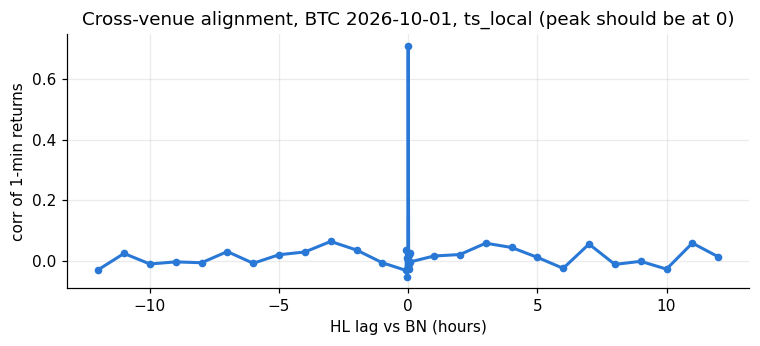

In [8]:
fig, ax = plt.subplots(figsize=(8, 3))
s = cross_venue_alignment(load_frames(c0, d0), JOIN_CLOCK)[1]
ax.plot(s.index / 60, s.values, marker="o", ms=4, color=SERIES[0])
ax.set(xlabel="HL lag vs BN (hours)", ylabel="corr of 1-min returns",
       title=f"Cross-venue alignment, {c0} {d0}, {JOIN_CLOCK} (peak should be at 0)")
plt.show()

### My read:
1. Is the local-minus-exchange offset per venue what I expect from where my collectors run, and is it stable
   across days?
2. Do any tables have a meaningful share of rows outside the UTC date, or non-monotone local timestamps?



## 1. Latency / stale window

**What and why.** The stale window is the time between a Binance move and when my HL quote can no longer be
picked off. It's bounded by order-ack, cancel and fill-notification latency, shown here at p50/p90/p99 by UTC hour.
`ack = ack_ts - send_ts` and `cancel = cancel_ack_ts - cancel_send_ts` are on one clock. `fill notification =
fill_notified_ts - fill_ts` mixes exchange and local clocks unless both are local, so any clock offset ends up in it.
Skipped if there's no own_orders data.

n   p50   p90   p99
coin metric                             
BTC  ack          5000  25.3  48.7  78.5
     cancel       3483  30.0  57.6  95.5
     fill_notify  1517  14.8  28.1  50.0
ETH  ack          5000  24.9  48.0  78.4
     cancel       3483  30.0  55.8  92.9
     fill_notify  1517  14.8  27.7  44.5

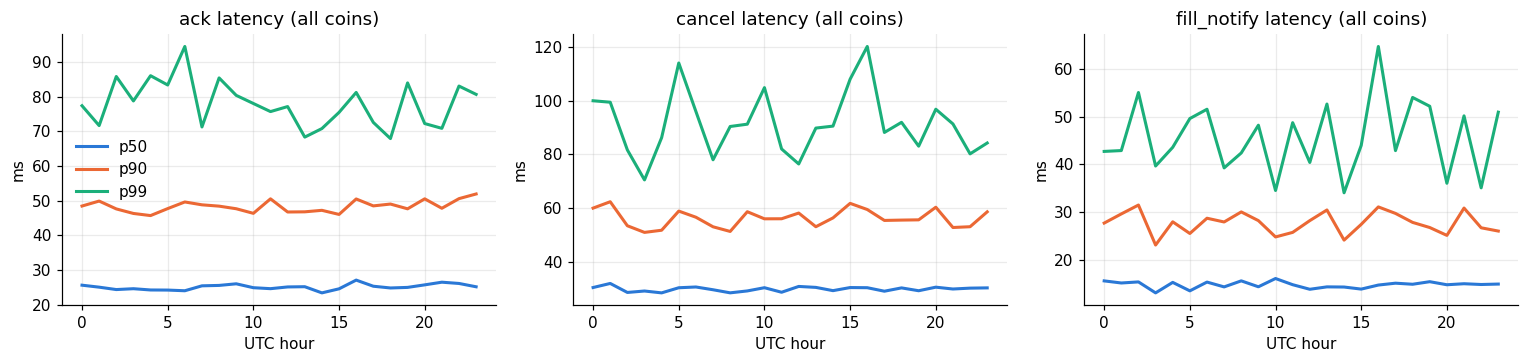

[PASS] 1. ack p50: 25.07 ms vs planted 25.0 ms
[PASS] 1. cancel p50: 29.98 ms vs planted 30.0 ms
[PASS] 1. fill_notify p50: 14.81 ms vs planted 15.0 ms


In [9]:
def own_latencies(coin, date):
    """Per-order latencies (ms) and UTC send hour for one coin-day; None if no own_orders."""
    o = load(coin, date, "own_orders")
    if o is None or o.empty:
        return None
    lat = lambda a, b: (o[a] - o[b]).astype("Float64").to_numpy(dtype=float, na_value=np.nan) / MS
    return pd.DataFrame({"coin": coin, "hour": (o.send_ts.astype("int64") // (3600 * S)) % 24,
                         "ack": lat("ack_ts", "send_ts"), "cancel": lat("cancel_ack_ts", "cancel_send_ts"),
                         "fill_notify": lat("fill_notified_ts", "fill_ts")})


lat_parts = [x for x in (own_latencies(c, d) for c, d in coin_days()) if x is not None]
LAT = pd.concat(lat_parts, ignore_index=True) if lat_parts else None
LAT_METRICS = ["ack", "cancel", "fill_notify"]
pct = lambda q: (lambda x: np.nanpercentile(x, q) if np.isfinite(x).any() else np.nan)

if LAT is None:
    print("own_orders empty or not configured: section 1 skipped (gate 1 will show n/a).")
else:
    long = LAT.melt(id_vars=["coin", "hour"], value_vars=LAT_METRICS, var_name="metric", value_name="ms")
    lat_summary = long.groupby(["coin", "metric"]).ms.agg(n="count", p50=pct(50), p90=pct(90), p99=pct(99))
    display(lat_summary.round(1))
    for coin in COINS:
        if coin in lat_summary.index.get_level_values(0):
            RESULTS["ack_latency_p99_ms"][coin] = lat_summary.loc[(coin, "ack"), "p99"]

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=False)
    by_hour = long.groupby(["metric", "hour"]).ms.agg(p50=pct(50), p90=pct(90), p99=pct(99))
    for ax, m in zip(axes, LAT_METRICS):
        for q, col in zip(["p50", "p90", "p99"], SERIES):
            ax.plot(by_hour.loc[m].index, by_hour.loc[m][q], label=q, color=col)
        ax.set(title=f"{m} latency (all coins)", xlabel="UTC hour", ylabel="ms")
    axes[0].legend()
    plt.tight_layout(); plt.show()

    if SYNTHETIC:
        for m, key in zip(LAT_METRICS, ["ack_ms", "cancel_ms", "fill_notify_ms"]):
            got = np.nanmedian(LAT[m])
            check(f"1. {m} p50", abs(got / SYNTH[key] - 1) < 0.10, f"{got:.2f} ms vs planted {SYNTH[key]} ms")

### My read:
1. Is my p99 cancel latency inside TAU, and in which hours does it stop being?
2. Does fill notification lag enough that I'd hedge late on the moves that matter?
3. Is the hour-of-day pattern mine (infra) or the venue's (load)?



## 2. Room before adverse selection

**What and why.** If the quoted HL half-spread doesn't cover round-trip fees, nothing downstream matters.
`room = half-spread (bps of mid) - round-trip fees`, where the round trip is the HL maker fee plus the `EXIT_LEG`
fee. The half-spread is time-weighted per minute (each quote held until the next update, capped at 60 s). Plots
show room over time, its distribution, and half-spread against 5-minute realised Binance volatility.

,minutes,half_spread_med_bps,fees_rt_bps,room_p10,room_med,room_p90,frac_minutes_room_pos
coin,,,,,,,
BTC,1440,1.223,6.5,-5.295,-5.277,-5.257,0.0
ETH,1440,1.223,6.5,-5.296,-5.277,-5.257,0.0


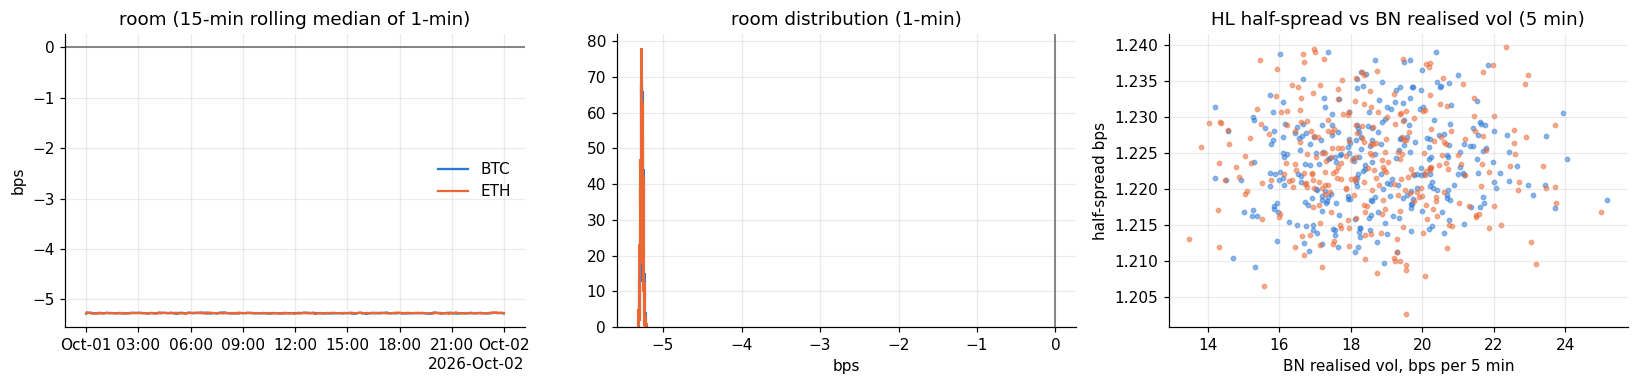

[PASS] 2. BTC HL half-spread: 1.223 bps vs planted median 1.2
[PASS] 2. ETH HL half-spread: 1.223 bps vs planted median 1.2


In [10]:
def time_weighted(ts, v, bucket_s, cap_s=60):
    """Time-weighted mean of a step series per bucket; a value counts until the next update (capped).
    A value that spans a bucket edge is credited to its start bucket."""
    dt = np.minimum(np.diff(ts, append=ts[-1]), cap_s * S).astype(float)
    g = pd.DataFrame({"b": ts // (bucket_s * S), "vw": v * dt, "w": dt}).groupby("b").sum()
    g = g[g.w > 0]
    return pd.Series((g.vw / g.w).to_numpy(), index=pd.to_datetime(g.index.to_numpy() * bucket_s * S, utc=True))


def fv_series(coin, date):
    """Fair value: Binance log-mid on JOIN_CLOCK, timestamps shifted by FV_LAG_MS (so FV(t) = mid(t - lag))."""
    b = load(coin, date, "book_binance", [JOIN_CLOCK, "bid_px", "ask_px"])
    return b[JOIN_CLOCK].to_numpy() + FV_LAG_MS * MS, np.log(((b.bid_px + b.ask_px) / 2).to_numpy())


def hl_book(coin, date, clock=JOIN_CLOCK):
    """HL top of book sorted by `clock`, with log-mid and half-spread in bps."""
    h = load(coin, date, "book_hyperliquid").sort_values(clock, kind="stable")
    return h.assign(lm=np.log((h.bid_px + h.ask_px) / 2), hs_bps=(h.ask_px - h.bid_px) / (h.ask_px + h.bid_px) * 1e4)


def room_coin_day(coin, date):
    """Per-minute HL half-spread and 5-minute (half-spread, BN realised vol) for one coin-day."""
    h = hl_book(coin, date)
    ts, hs = h[JOIN_CLOCK].to_numpy(), h.hs_bps.to_numpy()
    fts, flog = fv_series(coin, date)
    g = np.arange(fts[0] - fts[0] % S + S, fts[-1], S)   # 1 s grid for realised vol
    r = np.diff(asof_vals(fts, flog, g)) * 1e4
    rv = pd.Series(r ** 2, index=pd.to_datetime(g[1:], utc=True)).resample("5min").sum() ** 0.5
    return time_weighted(ts, hs, 60), pd.DataFrame({"hs_bps": time_weighted(ts, hs, 300), "rv_bps_5m": rv}).dropna()


ROOM_MIN, ROOM_RV = {}, {}
for coin, date in coin_days():
    m, r5 = room_coin_day(coin, date)
    ROOM_MIN.setdefault(coin, []).append(m)
    ROOM_RV.setdefault(coin, []).append(r5)
ROOM_MIN = {c: pd.concat(v) for c, v in ROOM_MIN.items()}
ROOM_RV = {c: pd.concat(v) for c, v in ROOM_RV.items()}
FEE_RT = roundtrip_fee_bps()

rows = []
for coin in COINS:
    room = ROOM_MIN[coin] - FEE_RT
    RESULTS["room_median_bps"][coin] = room.median()
    rows.append({"coin": coin, "minutes": len(room), "half_spread_med_bps": ROOM_MIN[coin].median(),
                 "fees_rt_bps": FEE_RT, "room_p10": room.quantile(.1), "room_med": room.median(),
                 "room_p90": room.quantile(.9), "frac_minutes_room_pos": (room > 0).mean()})
display(pd.DataFrame(rows).set_index("coin").round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for coin in COINS:
    room = ROOM_MIN[coin] - FEE_RT
    axes[0].plot(room.index, room.rolling(15, min_periods=1).median(), label=coin, color=COIN_COLOR[coin], lw=1.5)
    axes[1].hist(room, bins=60, histtype="step", label=coin, color=COIN_COLOR[coin], lw=2)
    axes[2].scatter(ROOM_RV[coin].rv_bps_5m, ROOM_RV[coin].hs_bps, s=8, alpha=.5, label=coin, color=COIN_COLOR[coin])
for ax in axes[:2]:
    ax.axhline(0, color="0.4", lw=1) if ax is axes[0] else ax.axvline(0, color="0.4", lw=1)
axes[0].set(title="room (15-min rolling median of 1-min)", ylabel="bps")
date_axis(axes[0])
axes[1].set(title="room distribution (1-min)", xlabel="bps")
axes[2].set(title="HL half-spread vs BN realised vol (5 min)", xlabel="BN realised vol, bps per 5 min",
            ylabel="half-spread bps")
axes[0].legend()
plt.tight_layout(); plt.show()

if SYNTHETIC:
    for coin in COINS:
        got = ROOM_MIN[coin].median()
        check(f"2. {coin} HL half-spread", abs(got / SYNTH["hl_half_spread_bps"] - 1) < 0.05,
              f"{got:.3f} bps vs planted median {SYNTH['hl_half_spread_bps']}")

### My read:
1. Is there room left after fees at my fee tier, and in what share of minutes?
2. Does the spread widen with volatility enough to pay for the extra adverse selection, or does it stay flat?



## 3. Adverse selection (kill test)

**What and why.** The markout of a public HL trade at horizon h is `side × (FV(t+h) - FV(t))`, in bps of FV,
where `side` is the aggressor (+1 buy). It's what the aggressor gained, so it's what a maker on the other side
lost relative to fair value. `t` is the trade's `JOIN_CLOCK` time, and FV is read with a backward as-of at
`t` and `t+h`. Trades whose `t + max horizon` runs past the end of the FV data are dropped. Splits: notional size
bucket, and the Binance move over `[t - PRE_WINDOW, t]` signed by aggressor (+ = the taker is trading in the
direction Binance already moved).

`net edge = half-spread at the trade - markout(TAU) - cost`, with `cost = round-trip fees` plus the Binance
half-spread at the trade when `EXIT_LEG = "binance_taker"`. The half-spread is the HL touch strictly before the
print, matched on exchange time (same venue). Means are reported both trade-weighted and notional-weighted, with
95% block-bootstrap CIs (`BOOT_BLOCK_S` blocks).

In [11]:
def trade_frame(coin, date):
    """HL trades plus the HL touch strictly before each print (same venue, exchange clock)."""
    t = load(coin, date, "trades_hyperliquid")
    hb = load(coin, date, "book_hyperliquid").sort_values("ts_exchange", kind="stable")
    i = asof_idx(hb.ts_exchange.to_numpy(), t.ts_exchange.to_numpy(), strict=True)
    t, i = t[i >= 0].reset_index(drop=True), i[i >= 0]
    bid, ask = hb.bid_px.to_numpy()[i], hb.ask_px.to_numpy()[i]
    return t.assign(bid_pre=bid, ask_pre=ask, hs_bps=(ask - bid) / (ask + bid) * 1e4, notional=t.px * t.sz)


def markout_frame(coin, date):
    """Trade-level markouts, prior BN move, cost and net edge at TAU for one coin-day."""
    t = trade_frame(coin, date)
    fts, flog = fv_series(coin, date)
    ts, side = t[JOIN_CLOCK].to_numpy(), t.aggressor_side.to_numpy()
    f0 = asof_vals(fts, flog, ts)
    valid = ts + max(HORIZONS) * MS <= fts[-1]          # no markout read off a frozen end-of-data FV
    for h in HORIZONS:
        t[f"mo_{h}"] = np.where(valid, side * (asof_vals(fts, flog, ts + h * MS) - f0) * 1e4, np.nan)
    t["bn_pre"] = side * (f0 - asof_vals(fts, flog, ts - PRE_W * MS)) * 1e4
    b = load(coin, date, "book_binance", [JOIN_CLOCK, "bid_px", "ask_px"])
    bn_hs = asof_vals(b[JOIN_CLOCK].to_numpy(), ((b.ask_px - b.bid_px) / (b.ask_px + b.bid_px) * 1e4).to_numpy(), ts)
    t["cost_bps"] = FEE_RT + (bn_hs if EXIT_LEG == "binance_taker" else 0.0)
    t["net_tau"] = t.hs_bps - t[f"mo_{TAU}"] - t.cost_bps
    t["size_b"] = pd.cut(t.notional, SIZE_BUCKETS_USD).astype(str)
    t["bn_b"] = pd.cut(t.bn_pre, BN_MOVE_BUCKETS_BPS).astype(str)
    return t


def markout_blocks(t, coin):
    """Block sums for every (metric, weight, split, bucket): all markout stats, at no more than block resolution."""
    ts, out = t[JOIN_CLOCK].to_numpy(), []
    for metric in [f"mo_{h}" for h in HORIZONS] + ["net_tau", "hs_bps", "cost_bps"]:
        x = t[metric].to_numpy(float)
        for wname, w in (("trade", None), ("notional", t.notional.to_numpy())):
            for split, b in (("all", np.full(len(t), "all")), ("size", t.size_b), ("bn_move", t.bn_b)):
                if split != "all" and not metric.startswith("mo_"):
                    continue
                out.append(block_sums(ts, x, w, {"bucket": b}).assign(coin=coin, metric=metric, weight=wname,
                                                                      split=split))
    return pd.concat(out, ignore_index=True)


MO_BLOCKS = []
for coin, date in coin_days():
    t = markout_frame(coin, date)
    MO_BLOCKS.append(markout_blocks(t, coin))
    del t
MO_BLOCKS = pd.concat(MO_BLOCKS, ignore_index=True)
MO = (MO_BLOCKS.groupby(["coin", "metric", "weight", "split", "bucket"], sort=False)
      .apply(mean_ci, include_groups=False).reset_index())
mo_all = MO[MO.split == "all"]

print(f"Markouts by horizon (bps; + = aggressor gained = maker lost). TAU = {TAU} ms")
display(mo_all[mo_all.metric.str.startswith("mo_")].pivot_table(
    index=["coin", "weight"], columns="metric", values=["mean", "lo", "hi"]).round(3))

net_rows = []
for coin in COINS:
    g = mo_all[(mo_all.coin == coin)].set_index(["metric", "weight"])
    for wname in ("trade", "notional"):
        net_rows.append({"coin": coin, "weight": wname, "half_spread": g.loc[("hs_bps", wname), "mean"],
                         f"markout_{TAU}ms": g.loc[(f"mo_{TAU}", wname), "mean"],
                         "cost": g.loc[("cost_bps", wname), "mean"], "net_edge": g.loc[("net_tau", wname), "mean"],
                         "net_lo": g.loc[("net_tau", wname), "lo"], "net_hi": g.loc[("net_tau", wname), "hi"],
                         "n_trades": int(g.loc[("net_tau", wname), "n"])})
    RESULTS["net_edge_tau_bps"][coin] = g.loc[("net_tau", "notional"), "mean"]
NET = pd.DataFrame(net_rows).set_index(["coin", "weight"])
print("Net edge per unit at TAU (bps), with 95% block-bootstrap CI")
display(NET.round(3))

Markouts by horizon (bps; + = aggressor gained = maker lost). TAU = 200 ms


hi                              lo                            mean                        
metric        mo_1000 mo_200 mo_30000 mo_5000 mo_1000 mo_200 mo_30000 mo_5000 mo_1000 mo_200 mo_30000 mo_5000
coin weight                                                                                                  
BTC  notional   0.627  0.630    0.803   0.666   0.558  0.576    0.527   0.538   0.591  0.602    0.665   0.604
     trade      0.609  0.605    0.638   0.626   0.580  0.579    0.538   0.572   0.595  0.592    0.587   0.599
ETH  notional   0.633  0.631    0.628   0.641   0.563  0.576    0.397   0.527   0.598  0.602    0.525   0.586
     trade      0.599  0.599    0.628   0.597   0.570  0.574    0.521   0.547   0.585  0.587    0.578   0.575

Net edge per unit at TAU (bps), with 95% block-bootstrap CI


half_spread  markout_200ms   cost  net_edge  net_lo  net_hi  n_trades
coin weight                                                                         
BTC  trade           1.226          0.592  6.807    -6.173  -6.186  -6.161     45068
     notional        1.226          0.602  6.808    -6.183  -6.212  -6.157     45068
ETH  trade           1.224          0.587  6.806    -6.169  -6.181  -6.155     45080
     notional        1.221          0.602  6.806    -6.187  -6.215  -6.160     45080

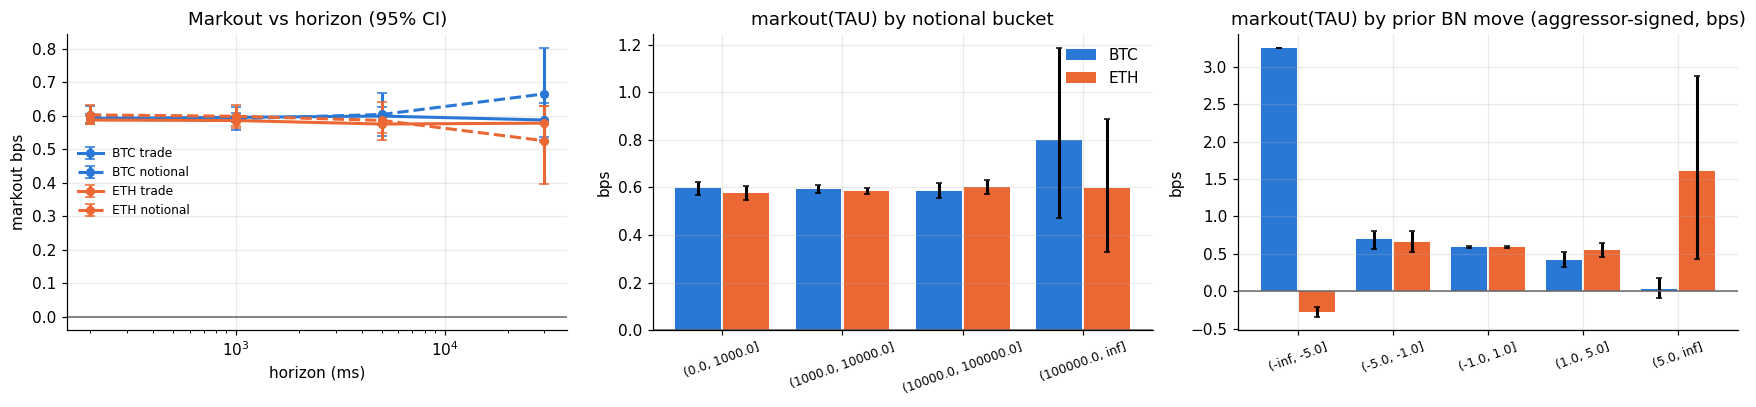

Counts per bucket (trades):


coin                             BTC      ETH
split   bucket                               
bn_move (-1.0, 1.0]          43975.0  43951.0
        (-5.0, -1.0]           490.0    490.0
        (-inf, -5.0]             1.0      2.0
        (1.0, 5.0]             597.0    633.0
        (5.0, inf]               5.0      4.0
size    (0.0, 1000.0]         8565.0   8720.0
        (1000.0, 10000.0]    27908.0  27822.0
        (10000.0, 100000.0]   8532.0   8451.0
        (100000.0, inf]         63.0     87.0

[PASS] 3. BTC markout(200ms): 0.592 bps vs planted informed_frac*markout = 0.60
[PASS] 3. BTC markout(30000ms): 0.587 bps vs planted informed_frac*markout = 0.60
[PASS] 3. BTC net edge: -6.173 bps vs planted -6.182
[PASS] 3. ETH markout(200ms): 0.587 bps vs planted informed_frac*markout = 0.60
[PASS] 3. ETH markout(30000ms): 0.578 bps vs planted informed_frac*markout = 0.60
[PASS] 3. ETH net edge: -6.169 bps vs planted -6.182
Public data only identifies informed_frac × markout, not the two separately.


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for coin in COINS:
    for wname, ls in (("trade", "-"), ("notional", "--")):
        d = mo_all[(mo_all.coin == coin) & (mo_all.weight == wname) & mo_all.metric.str.startswith("mo_")]
        h = d.metric.str[3:].astype(int)
        axes[0].errorbar(h, d["mean"], yerr=[d["mean"] - d.lo, d.hi - d["mean"]], ls=ls, marker="o", ms=5,
                         capsize=3, color=COIN_COLOR[coin], label=f"{coin} {wname}")
axes[0].set(xscale="log", xlabel="horizon (ms)", ylabel="markout bps", title="Markout vs horizon (95% CI)")
axes[0].axhline(0, color="0.4", lw=1)
axes[0].legend(fontsize=8)
for ax, split, title in ((axes[1], "size", "markout(TAU) by notional bucket"),
                         (axes[2], "bn_move", "markout(TAU) by prior BN move (aggressor-signed, bps)")):
    d = MO[(MO.split == split) & (MO.metric == f"mo_{TAU}") & (MO.weight == "trade")]
    buckets = [b for b in d.bucket.unique() if b != "nan"]
    buckets = sorted(buckets, key=lambda s: float(s.strip("(]").split(",")[0]))
    x = np.arange(len(buckets))
    for k, coin in enumerate(COINS):
        dc = d[d.coin == coin].set_index("bucket").reindex(buckets)
        ax.bar(x + (k - (len(COINS) - 1) / 2) * 0.8 / len(COINS), dc["mean"], width=0.8 / len(COINS) - 0.02,
               yerr=[dc["mean"] - dc.lo, dc.hi - dc["mean"]], capsize=2, color=COIN_COLOR[coin], label=coin)
    ax.set_xticks(x, buckets, rotation=20, fontsize=8)
    ax.axhline(0, color="0.4", lw=1)
    ax.set(title=title, ylabel="bps")
axes[1].legend()
plt.tight_layout(); plt.show()

print("Counts per bucket (trades):")
display(MO[(MO.split != "all") & (MO.metric == f"mo_{TAU}") & (MO.weight == "trade")]
        .pivot_table(index=["split", "bucket"], columns="coin", values="n"))

if SYNTHETIC:
    truth_mo = SYNTH["informed_frac"] * SYNTH["informed_markout_bps"]
    hs_mean = SYNTH["hl_half_spread_bps"] * math.exp(SYNTH["spread_noise"] ** 2 / 2)
    bn_mean = SYNTH["bn_half_spread_bps"] * math.exp(SYNTH["spread_noise"] ** 2 / 2)
    for coin in COINS:
        g = mo_all[(mo_all.coin == coin) & (mo_all.weight == "trade")].set_index("metric")
        for h in (TAU, max(HORIZONS)):
            got = g.loc[f"mo_{h}", "mean"]
            check(f"3. {coin} markout({h}ms)", abs(got - truth_mo) < 0.15,
                  f"{got:.3f} bps vs planted informed_frac*markout = {truth_mo:.2f}")
        want = hs_mean - truth_mo - FEE_RT - bn_mean
        got = g.loc["net_tau", "mean"]
        check(f"3. {coin} net edge", abs(got - want) < 0.15, f"{got:.3f} bps vs planted {want:.3f}")
    print("Public data only identifies informed_frac × markout, not the two separately.")

### My read:
1. Is this coin's net edge positive at TAU, and how much worse should I expect my own fills to be than the
   average public trade?
2. Which bucket carries the toxicity (large prints, or takers following a Binance move I'd be stale on)?
   Could I avoid it with a size or move filter without losing most of the volume?
3. Does the markout keep growing past TAU (information) or flatten (pure latency)?



## 4. Getting out

**What and why.** After a passive fill I either wait for an offsetting trade on HL or hedge on Binance.
- **Offset hazard.** Each aggressor event (first print per timestamp and side) makes me the maker on the other
  side. Wait time = time until an opposite-aggressor print at or better than the target. With
  `OFFSET_TARGET="entry_quote"` the target is the opposite HL touch at entry (full spread); with `"entry_px"` it's
  my fill price (scratch). Waits are censored at `OFFSET_MAX_WAIT_S`, and entries within that of the data end are
  dropped. Each wait is labelled by whether Binance moved with or against my position over `OFFSET_BN_WINDOW_MS`
  after entry. That label is descriptive and conditions on the future.
- **Basis half-life.** `basis = log HL mid - log FV` in bps, sampled every `BASIS_RESAMPLE_S` on `JOIN_CLOCK`.
  AR(1) by OLS on pairs within each day, half-life `= -ln2 · dt / ln φ`, with a CI from bootstrapping 30-minute
  blocks of pairs. Lag noise (HL staleness against Binance) biases φ, and so the half-life, downward. As a
  diagnostic, `φ_robust = γ(2)/γ(1)` is reported alongside: it's insensitive to white noise.
- **Binance taker cost** at `HEDGE_SIZE_USD`: half-spread + taker fee. With L1 data only, that's a *lower
  bound* whenever the size exceeds the touch, so the share of time that happens is shown.

In [13]:
WAIT_EDGES = np.concatenate([[0], np.geomspace(0.01, OFFSET_MAX_WAIT_S, 80)])


def offset_waits(t, fts, flog):
    """Seconds to offset each entry (inf = not within max wait) and the BN with/against label."""
    t = t.sort_values("ts_exchange", kind="stable").reset_index(drop=True)
    tx, px, sd = t.ts_exchange.to_numpy(), t.px.to_numpy(), t.aggressor_side.to_numpy()
    ev = t.drop_duplicates(["ts_exchange", "aggressor_side"], keep="first")
    ev = ev[ev.ts_exchange <= tx[-1] - OFFSET_MAX_WAIT_S * S]
    ev_t, ev_s = ev.ts_exchange.to_numpy(), ev.aggressor_side.to_numpy()
    # maker position = -aggressor; long (+1) exits on a buyer-initiated print at >= target, short on a sell at <=
    target = (np.where(ev_s == -1, ev.ask_pre.to_numpy(), ev.bid_pre.to_numpy()) if OFFSET_TARGET == "entry_quote"
              else ev.px.to_numpy())
    wait = np.full(len(ev), np.inf)
    for s_in in (-1, 1):
        ex = sd == -s_in
        ex_t, ex_p = tx[ex], px[ex]
        sel = np.flatnonzero(ev_s == s_in)
        lo = np.searchsorted(ex_t, ev_t[sel], "right")
        hi = np.searchsorted(ex_t, ev_t[sel] + OFFSET_MAX_WAIT_S * S, "right")
        for j, a, b in zip(sel, lo, hi):   # one short window per entry; vectorised inside the window
            if b > a:
                seg = ex_p[a:b]
                hit = seg >= target[j] * (1 - 1e-9) if s_in == -1 else seg <= target[j] * (1 + 1e-9)
                k = int(np.argmax(hit))
                if hit[k]:
                    wait[j] = (ex_t[a + k] - ev_t[j]) / S
    tj = ev[JOIN_CLOCK].to_numpy()
    bn = -ev_s * (asof_vals(fts, flog, tj + OFF_BN_W * MS) - asof_vals(fts, flog, tj))
    label = np.where(bn > 0, "with", np.where(bn < 0, "against", "flat"))
    return wait, label


def wait_hist(wait, label):
    """Histogram counts of waits per label (last column = censored): small enough to pool over days."""
    out = {}
    for lab in ("all", "with", "against"):
        w = wait if lab == "all" else wait[label == lab]
        out[lab] = np.append(np.histogram(w[np.isfinite(w)], WAIT_EDGES)[0], np.isinf(w).sum())
    return out


def survival(counts):
    """P(wait > edge) at each upper bin edge, from binned counts with censoring at the max wait."""
    return 1 - np.cumsum(counts[:-1]) / counts.sum()


def basis_series(coin, date, fts, flog):
    """Basis (bps) on a BASIS_RESAMPLE_S grid over the overlap of both feeds."""
    h = hl_book(coin, date)
    hts, hlm = h[JOIN_CLOCK].to_numpy(), h.lm.to_numpy()
    g = np.arange(max(hts[0], fts[0]) + BASIS_RESAMPLE_S * S, min(hts[-1], fts[-1]), BASIS_RESAMPLE_S * S)
    return g, (asof_vals(hts, hlm, g) - asof_vals(fts, flog, g)) * 1e4


def bn_cost_coin_day(coin, date):
    """Per-minute BN half-spread and share of time the touch is smaller than HEDGE_SIZE_USD."""
    b = load(coin, date, "book_binance").sort_values(JOIN_CLOCK, kind="stable")
    ts = b[JOIN_CLOCK].to_numpy()
    hs = ((b.ask_px - b.bid_px) / (b.ask_px + b.bid_px) * 1e4).to_numpy()
    thin = (np.minimum(b.bid_px * b.bid_sz, b.ask_px * b.ask_sz) < HEDGE_SIZE_USD).to_numpy(float)
    return time_weighted(ts, hs, 60), time_weighted(ts, thin, 60)


WAITS, BASIS, BNC = {}, {}, {}
for coin, date in coin_days():
    fts, flog = fv_series(coin, date)
    w, lab = offset_waits(trade_frame(coin, date), fts, flog)
    hcounts = wait_hist(w, lab)
    WAITS[coin] = {k: WAITS.get(coin, {}).get(k, 0) + v for k, v in hcounts.items()}
    g, b = basis_series(coin, date, fts, flog)
    BASIS.setdefault(coin, []).append((date, g, b))
    BNC.setdefault(coin, []).append(bn_cost_coin_day(coin, date))


def ar1_half_life(series_list, dt_s, block=180, seed=SEED):
    """Pooled within-day AR(1): phi, half-life (s) with block-bootstrap CI, and the noise-robust phi."""
    rows, rob = [], []
    for _, _, b in series_list:
        x, y = b[:-1], b[1:]
        ok = np.isfinite(x) & np.isfinite(y)
        x, y = x[ok], y[ok]
        blk = np.arange(len(x)) // block
        rows.append(pd.DataFrame({"blk": blk, "n": 1, "sx": x, "sy": y, "sxx": x * x, "sxy": x * y})
                    .groupby("blk").sum())
        z = b[np.isfinite(b)] - np.nanmean(b)
        rob.append((np.dot(z[:-2], z[2:]), np.dot(z[:-1], z[1:])))
    B = pd.concat(rows, ignore_index=True).to_numpy()

    def fit(s):
        n, sx, sy, sxx, sxy = s
        return (sxy - sx * sy / n) / (sxx - sx * sx / n)
    hl = lambda ph: -math.log(2) * dt_s / math.log(ph) if 0 < ph < 1 else np.nan
    phi = fit(B.sum(0))
    idx = np.random.default_rng(seed).integers(0, len(B), (N_BOOT, len(B)))
    boots = np.array([hl(fit(B[i].sum(0))) for i in idx])
    phi_r = sum(a for a, _ in rob) / sum(b for _, b in rob)
    return {"phi": phi, "half_life_s": hl(phi), "hl_lo": np.nanpercentile(boots, 2.5),
            "hl_hi": np.nanpercentile(boots, 97.5), "phi_robust": phi_r, "half_life_robust_s": hl(phi_r),
            "n_pairs": int(B[:, 0].sum())}


out_rows = []
for coin in COINS:
    surv = survival(WAITS[coin]["all"])
    med = WAIT_EDGES[1:][np.argmax(surv <= 0.5)] if (surv <= 0.5).any() else np.inf
    ar = ar1_half_life(BASIS[coin], BASIS_RESAMPLE_S)
    hs_min = pd.concat([x[0] for x in BNC[coin]])
    thin = pd.concat([x[1] for x in BNC[coin]])
    RESULTS["offset_median_s"][coin] = med
    RESULTS["basis_half_life_s"][coin] = ar["half_life_s"]
    out_rows.append({"coin": coin, "entries": int(WAITS[coin]["all"].sum()),
                     "offset_median_s": med, f"P(no offset in {OFFSET_MAX_WAIT_S}s)": surv[-1],
                     **{k: ar[k] for k in ("half_life_s", "hl_lo", "hl_hi", "half_life_robust_s", "n_pairs")},
                     "bn_half_spread_med_bps": hs_min.median(),
                     "bn_taker_cost_med_bps": hs_min.median() + FEES_BPS["binance"]["taker"],
                     f"frac_time_touch<{HEDGE_SIZE_USD:,}$": thin.mean()})
GETOUT = pd.DataFrame(out_rows).set_index("coin")
display(GETOUT.round(3))

,entries,offset_median_s,P(no offset in 60s),half_life_s,hl_lo,hl_hi,half_life_robust_s,n_pairs,bn_half_spread_med_bps,bn_taker_cost_med_bps,"frac_time_touch<50,000$"
coin,,,,,,,,,,,
BTC,42892,9.229,0.184,56.409,52.305,59.628,59.276,8638,0.306,5.306,0.006
ETH,42956,9.229,0.180,53.836,48.839,59.274,56.005,8638,0.306,5.306,0.005


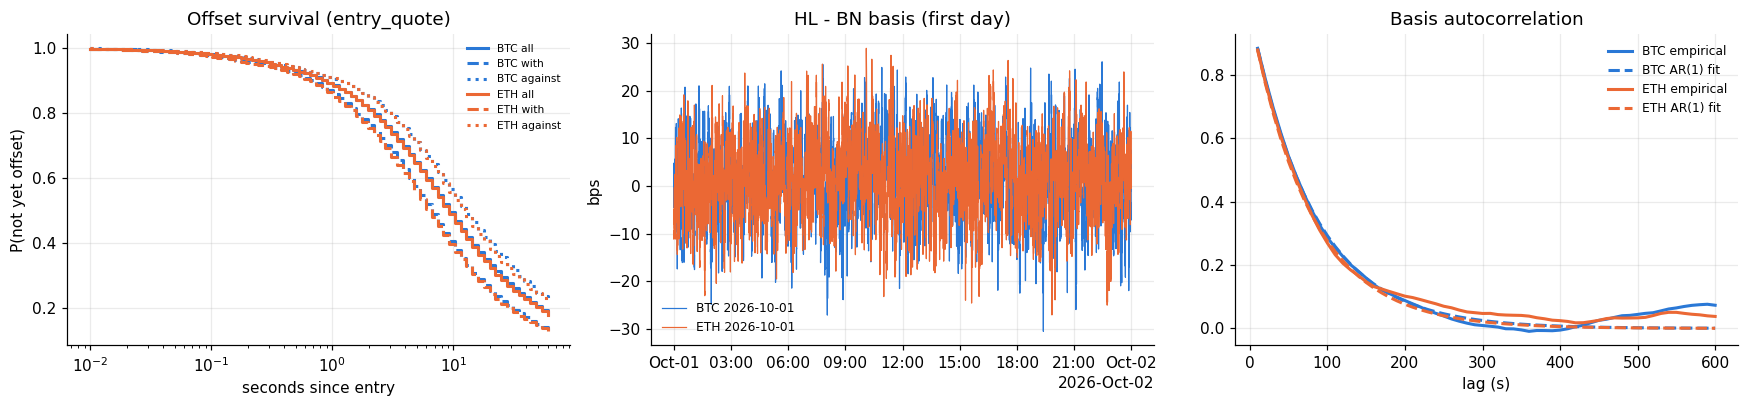

[PASS] 4. BTC basis half-life: 56.4 s vs planted 60.0 s (robust 59.3 s)
[PASS] 4. BTC BN half-spread: 0.306 bps vs planted 0.3
[PASS] 4. ETH basis half-life: 53.8 s vs planted 60.0 s (robust 56.0 s)
[PASS] 4. ETH BN half-spread: 0.306 bps vs planted 0.3


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for coin in COINS:
    for lab, ls in (("all", "-"), ("with", "--"), ("against", ":")):
        axes[0].step(WAIT_EDGES[1:], survival(WAITS[coin][lab]), where="post", ls=ls, color=COIN_COLOR[coin],
                     label=f"{coin} {lab}")
    date, g, b = BASIS[coin][0]
    axes[1].plot(pd.to_datetime(g, utc=True), b, lw=0.8, color=COIN_COLOR[coin], label=f"{coin} {date}")
    lags = np.arange(1, 61)
    z = b[np.isfinite(b)] - np.nanmean(b)
    acf = [np.dot(z[:-k], z[k:]) / np.dot(z, z) for k in lags]
    phi = GETOUT.loc[coin, "half_life_s"]
    axes[2].plot(lags * BASIS_RESAMPLE_S, acf, color=COIN_COLOR[coin], label=f"{coin} empirical")
    axes[2].plot(lags * BASIS_RESAMPLE_S, 0.5 ** (lags * BASIS_RESAMPLE_S / phi), ls="--", color=COIN_COLOR[coin],
                 label=f"{coin} AR(1) fit")
axes[0].set(xscale="log", xlabel="seconds since entry", ylabel="P(not yet offset)",
            title=f"Offset survival ({OFFSET_TARGET})")
axes[0].legend(fontsize=7)
axes[1].set(title="HL - BN basis (first day)", ylabel="bps")
date_axis(axes[1])
axes[1].legend(fontsize=8)
axes[2].set(title="Basis autocorrelation", xlabel="lag (s)")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

if SYNTHETIC:
    for coin in COINS:
        got = GETOUT.loc[coin, "half_life_s"]
        check(f"4. {coin} basis half-life", abs(got / SYNTH["basis_half_life_s"] - 1) < 0.20,
              f"{got:.1f} s vs planted {SYNTH['basis_half_life_s']} s "
              f"(robust {GETOUT.loc[coin, 'half_life_robust_s']:.1f} s)")
        got = GETOUT.loc[coin, "bn_half_spread_med_bps"]
        check(f"4. {coin} BN half-spread", abs(got / SYNTH["bn_half_spread_bps"] - 1) < 0.05,
              f"{got:.3f} bps vs planted {SYNTH['bn_half_spread_bps']}")

### My read:
1. When Binance moves against me, how long do I sit on inventory before HL offers an exit, and is hedging on
   Binance cheaper than that wait?
2. Is the basis half-life short enough that hedging and unwinding later costs less than crossing on HL?
3. How far apart are the OLS and robust half-lives, and what does that say about noise in my basis?



## 5. Lead-lag

**What and why.** If HL follows Binance with a delay, a move on Binance tells me where HL is going, and tells
everyone faster than me too.
- Cross-correlation of mid log-returns on an `XCORR_GRID_MS` grid (`JOIN_CLOCK`, backward as-of), computed in
  hourly chunks so memory stays small. Lag > 0 means the HL return comes after the BN return, i.e. Binance leads.
- Fraction of a Binance move reflected in HL: the slope of `HL(t+h) - HL(t-W)` on `BN(t) - BN(t-W)`
  (`W = REFLECT_WINDOW_MS`, non-overlapping windows), at each `h` in `REFLECT_H_MS`.
- Distribution of Binance mid moves over non-overlapping TAU windows, the p90/p99 tails, and the UTC hours
  where moves above the `BIG_MOVE_Q` quantile land.

In [15]:
assert all(l % XCORR_GRID_MS == 0 for l in XCORR_LAGS_MS), "XCORR_LAGS_MS must be multiples of XCORR_GRID_MS"
MOVE_EDGES = np.concatenate([[0], np.geomspace(1e-3, 1e3, 400)])


def xcorr_sums(hts, hlm, fts, flog):
    """Pooled-correlation sums (n, sx, sy, sxx, syy, sxy) per lag between BN and HL grid returns."""
    step, K = XCORR_GRID_MS * MS, np.array(XCORR_LAGS_MS) // XCORR_GRID_MS
    kmax = int(np.abs(K).max())
    start, end = max(hts[0], fts[0]), min(hts[-1], fts[-1])
    sums = np.zeros((len(K), 6))
    for a in range(int(start), int(end), 3600 * S):
        nb = int(math.ceil((min(a + 3600 * S, end) - a) / step))
        g = a + (np.arange(nb + 2 * kmax + 1, dtype=np.int64) - kmax) * step   # int64: Windows default is int32
        rb, rh = np.diff(asof_vals(fts, flog, g)), np.diff(asof_vals(hts, hlm, g))
        x = rb[kmax: kmax + nb]                       # BN returns starting inside [a, a + 1h)
        for j, k in enumerate(K):
            y = rh[kmax + k: kmax + k + nb]           # HL return k steps later
            ok = np.isfinite(x) & np.isfinite(y)
            xo, yo = x[ok], y[ok]
            sums[j] += [ok.sum(), xo.sum(), yo.sum(), xo @ xo, yo @ yo, xo @ yo]
    return sums


def corr_from_sums(s):
    """Pearson correlation from pooled sums."""
    n, sx, sy, sxx, syy, sxy = s.T
    return (sxy - sx * sy / n) / np.sqrt((sxx - sx ** 2 / n) * (syy - sy ** 2 / n))


def reflect_sums(hts, hlm, fts, flog):
    """Regression sums of HL response on the BN move, per horizon h (n, sx, sy, sxx, sxy)."""
    W = REFLECT_WINDOW_MS * MS
    g = np.arange(max(hts[0], fts[0]) + W, min(hts[-1], fts[-1]) - max(REFLECT_H) * MS, W)
    x = (asof_vals(fts, flog, g) - asof_vals(fts, flog, g - W)) * 1e4
    out = []
    for h in REFLECT_H:
        y = (asof_vals(hts, hlm, g + h * MS) - asof_vals(hts, hlm, g - W)) * 1e4
        ok = np.isfinite(x) & np.isfinite(y)
        out.append([ok.sum(), x[ok].sum(), y[ok].sum(), x[ok] @ x[ok], x[ok] @ y[ok]])
    return np.array(out)


def tau_moves_hist(fts, flog):
    """24 x len(MOVE_EDGES)-1 counts of |BN move| over non-overlapping TAU windows, by UTC hour."""
    g = np.arange(fts[0] + TAU * MS, fts[-1], TAU * MS)
    m = np.abs(np.diff(asof_vals(fts, flog, g))) * 1e4
    hour = ((g[1:] // (3600 * S)) % 24).astype(int)
    return np.histogram2d(hour, m, bins=[np.arange(25), MOVE_EDGES])[0]


XC, RF, MV = {}, {}, {}
for coin, date in coin_days():
    fts, flog = fv_series(coin, date)
    h = hl_book(coin, date)
    hts, hlm = h[JOIN_CLOCK].to_numpy(), h.lm.to_numpy()
    XC[coin] = XC.get(coin, 0) + xcorr_sums(hts, hlm, fts, flog)
    RF[coin] = RF.get(coin, 0) + reflect_sums(hts, hlm, fts, flog)
    MV[coin] = MV.get(coin, 0) + tau_moves_hist(fts, flog)
    del h, hts, hlm


def hist_quantile(counts, q):
    """Quantile from binned counts (upper bin edge)."""
    c = np.cumsum(counts) / counts.sum()
    return MOVE_EDGES[1:][np.searchsorted(c, q)]


ll_rows = []
for coin in COINS:
    cc = corr_from_sums(XC[coin])
    n, sx, sy, sxx, sxy = RF[coin].T
    frac = (sxy - sx * sy / n) / (sxx - sx ** 2 / n)
    tot = MV[coin].sum(0)
    p90, p99, pbig = hist_quantile(tot, .9), hist_quantile(tot, .99), hist_quantile(tot, BIG_MOVE_Q)
    RESULTS["frac_reflected_tau"][coin] = frac[REFLECT_H.index(TAU)]
    RESULTS["bn_move_tau_p99_bps"][coin] = p99
    ll_rows.append({"coin": coin, "peak_lag_ms": XCORR_LAGS_MS[int(np.nanargmax(cc))], "peak_corr": np.nanmax(cc),
                    **{f"frac_reflected_h{h}": f for h, f in zip(REFLECT_H, frac)},
                    f"bn_move_{TAU}ms_p90_bps": p90, f"bn_move_{TAU}ms_p99_bps": p99})
LEADLAG = pd.DataFrame(ll_rows).set_index("coin")
display(LEADLAG.round(3))

,peak_lag_ms,peak_corr,frac_reflected_h0,frac_reflected_h200,frac_reflected_h1000,frac_reflected_h5000,bn_move_200ms_p90_bps,bn_move_200ms_p99_bps
coin,,,,,,,,
BTC,290,0.054,0.607,0.814,1.002,0.997,0.428,3.081
ETH,300,0.057,0.611,0.816,0.999,0.996,0.428,3.081


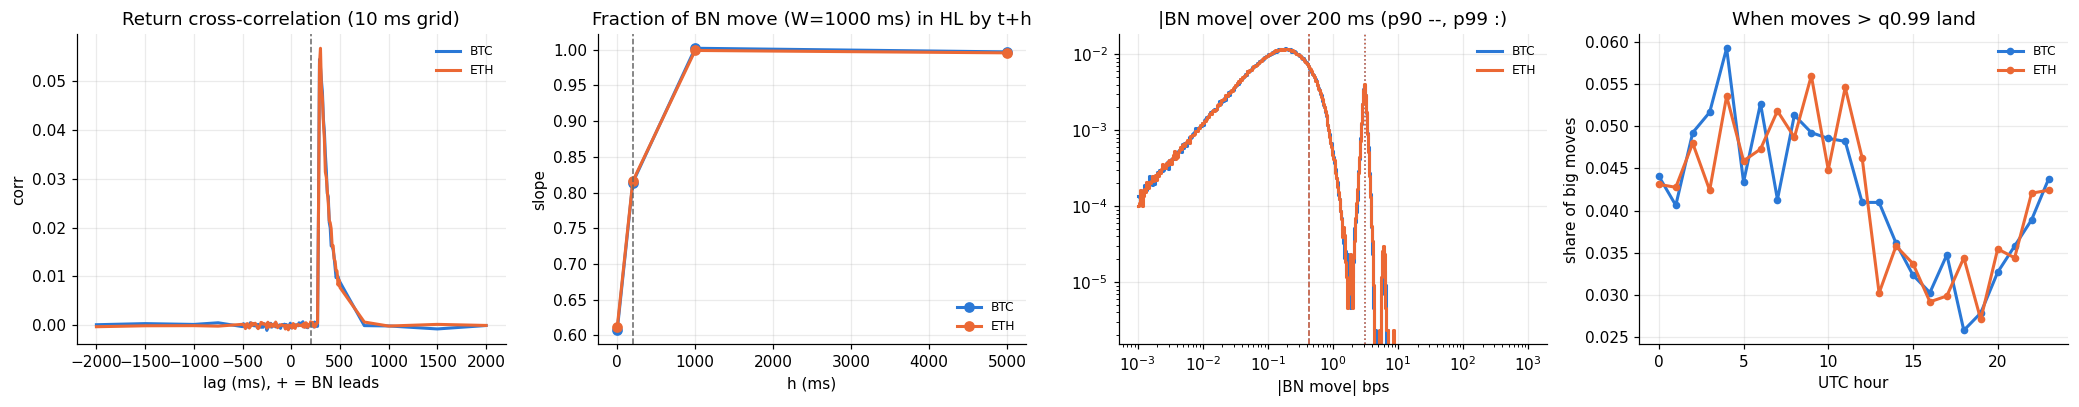

[PASS] 5. BTC lead-lag peak: 290 ms vs planted 282.5 ms on ts_local
[PASS] 5. BTC fully reflected at 5000 ms: 0.997 vs 1
[PASS] 5. ETH lead-lag peak: 300 ms vs planted 282.5 ms on ts_local
[PASS] 5. ETH fully reflected at 5000 ms: 0.996 vs 1


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.8))
for coin in COINS:
    axes[0].plot(XCORR_LAGS_MS, corr_from_sums(XC[coin]), color=COIN_COLOR[coin], label=coin)
    n, sx, sy, sxx, sxy = RF[coin].T
    axes[1].plot(REFLECT_H, (sxy - sx * sy / n) / (sxx - sx ** 2 / n), marker="o", color=COIN_COLOR[coin], label=coin)
    tot = MV[coin].sum(0)
    centers = np.sqrt(MOVE_EDGES[1:-1] * MOVE_EDGES[2:])
    axes[2].step(centers, tot[1:] / tot.sum(), where="mid", color=COIN_COLOR[coin], label=coin)
    for q, ls in ((.9, "--"), (.99, ":")):
        axes[2].axvline(hist_quantile(tot, q), color=COIN_COLOR[coin], ls=ls, lw=1)
    big = MV[coin][:, MOVE_EDGES[:-1] >= hist_quantile(tot, BIG_MOVE_Q)].sum(1)
    axes[3].plot(np.arange(24), big / big.sum(), marker="o", ms=4, color=COIN_COLOR[coin], label=coin)
axes[0].axvline(TAU, color="0.4", lw=1, ls="--")
axes[0].set(xlabel="lag (ms), + = BN leads", ylabel="corr", title=f"Return cross-correlation ({XCORR_GRID_MS} ms grid)")
axes[1].axvline(TAU, color="0.4", lw=1, ls="--")
axes[1].set(xlabel="h (ms)", ylabel="slope", title=f"Fraction of BN move (W={REFLECT_WINDOW_MS} ms) in HL by t+h")
axes[2].set(xscale="log", yscale="log", xlabel="|BN move| bps", title=f"|BN move| over {TAU} ms (p90 --, p99 :)")
axes[3].set(xlabel="UTC hour", ylabel="share of big moves", title=f"When moves > q{BIG_MOVE_Q} land")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

if SYNTHETIC:
    for coin in COINS:
        want = TRUTH[(coin, DATES[0])]["lag_local_ms"] if JOIN_CLOCK == "ts_local" else SYNTH["hl_lag_ms"]
        got = LEADLAG.loc[coin, "peak_lag_ms"]
        check(f"5. {coin} lead-lag peak", abs(got - want) <= 30, f"{got} ms vs planted {want:.1f} ms on {JOIN_CLOCK}")
        f_long = LEADLAG.loc[coin, f"frac_reflected_h{max(REFLECT_H)}"]
        check(f"5. {coin} fully reflected at {max(REFLECT_H)} ms", abs(f_long - 1) < 0.05, f"{f_long:.3f} vs 1")

### My read:
1. Is the lag between Binance and HL longer than my TAU? If it is, who is repricing HL before me?
2. What share of a Binance move is still unreflected after TAU, and is that what my quotes get picked off on?
3. Do the big TAU moves cluster in hours I could just stop quoting?



## 6. Capacity

**What and why.** Edge per unit means little without volume. My quote = the HL touch strictly before each print
(exchange clock, same venue). **Touch** volume = prints at or through my level (optimistic fill bound).
**Through** volume = prints strictly through it (conservative). Each print is capped at `QUOTE_SIZE_USD` if set.
`$/day = mean daily volume × CAPACITY_SHARE × net edge (notional-weighted, bps) / 1e4`, using the section 3 net
edge for all fills. Through-fills are likely more toxic than average, so the through bound is optimistic on edge.

,days,touch_usd_day,through_usd_day,net_edge_bps,usd_day_touch,usd_day_touch_lo,usd_day_touch_hi,usd_day_through,usd_day_through_lo,usd_day_through_hi
coin,,,,,,,,,,
BTC,1,297286663.8,48844827.9,-6.2,-183825.8,-184680.9,-183047.4,-30203.0,-30343.5,-30075.1
ETH,1,299647579.3,50449110.7,-6.2,-185395.5,-186243.8,-184582.5,-31213.5,-31356.3,-31076.6


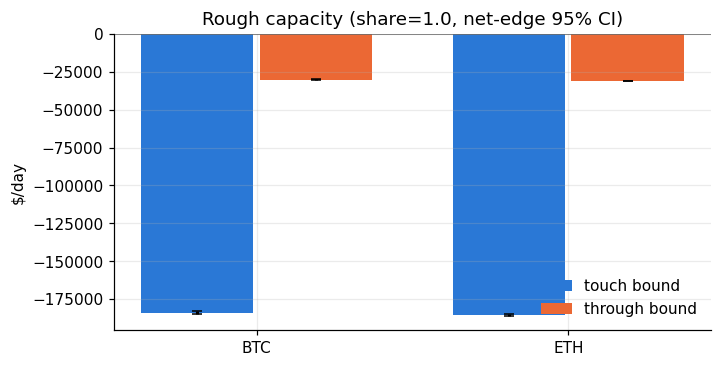

[PASS] 6. BTC touch volume: 297,286,664 vs planted 297,286,664
[PASS] 6. BTC through volume: 48,844,828 vs planted 48,844,828
[PASS] 6. ETH touch volume: 299,647,579 vs planted 299,647,579
[PASS] 6. ETH through volume: 50,449,111 vs planted 50,449,111


In [17]:
def capacity_coin_day(coin, date):
    """Touch and through notional (USD) for one coin-day."""
    t = trade_frame(coin, date)
    buy = t.aggressor_side.to_numpy() == 1
    px, bid, ask = t.px.to_numpy(), t.bid_pre.to_numpy(), t.ask_pre.to_numpy()
    touch = np.where(buy, px >= ask * (1 - 1e-9), px <= bid * (1 + 1e-9))
    through = np.where(buy, px > ask * (1 + 1e-9), px < bid * (1 - 1e-9))
    v = t.notional.to_numpy() if QUOTE_SIZE_USD is None else np.minimum(t.notional.to_numpy(), QUOTE_SIZE_USD)
    return {"coin": coin, "date": date, "touch_usd": v[touch].sum(), "through_usd": v[through].sum(),
            "total_usd": t.notional.sum()}


CAP_DAYS = pd.DataFrame([capacity_coin_day(c, d) for c, d in coin_days()])
cap_rows = []
for coin in COINS:
    d = CAP_DAYS[CAP_DAYS.coin == coin]
    ne = NET.loc[(coin, "notional")]
    row = {"coin": coin, "days": len(d), "touch_usd_day": d.touch_usd.mean(), "through_usd_day": d.through_usd.mean(),
           "net_edge_bps": ne.net_edge}
    for bound in ("touch", "through"):
        vol = row[f"{bound}_usd_day"] * CAPACITY_SHARE / 1e4
        row[f"usd_day_{bound}"], row[f"usd_day_{bound}_lo"], row[f"usd_day_{bound}_hi"] = \
            vol * ne.net_edge, vol * ne.net_lo, vol * ne.net_hi
        RESULTS[f"capacity_usd_day_{bound}"][coin] = row[f"usd_day_{bound}"]
    cap_rows.append(row)
CAP = pd.DataFrame(cap_rows).set_index("coin")
display(CAP.round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(COINS))
for k, bound in enumerate(("touch", "through")):
    y = CAP[f"usd_day_{bound}"]
    ax.bar(x + (k - .5) * 0.38, y, width=0.36, color=SERIES[k], label=f"{bound} bound",
           yerr=[y - CAP[f"usd_day_{bound}_lo"], CAP[f"usd_day_{bound}_hi"] - y], capsize=3)
ax.set_xticks(x, COINS)
ax.axhline(0, color="0.4", lw=1)
ax.set(ylabel="$/day", title=f"Rough capacity (share={CAPACITY_SHARE}, net-edge 95% CI)")
ax.legend()
plt.show()

if SYNTHETIC:
    for coin in COINS:
        d = CAP_DAYS[CAP_DAYS.coin == coin].iloc[0]
        tr = TRUTH[(coin, d.date)]
        if QUOTE_SIZE_USD is None:
            check(f"6. {coin} touch volume", abs(d.touch_usd / tr["touch_usd"] - 1) < 1e-6,
                  f"{d.touch_usd:,.0f} vs planted {tr['touch_usd']:,.0f}")
            check(f"6. {coin} through volume", abs(d.through_usd / tr["through_usd"] - 1) < 1e-6,
                  f"{d.through_usd:,.0f} vs planted {tr['through_usd']:,.0f}")

### My read:
1. Does capacity survive under the through bound, or only under touch?
2. What queue share is realistic for me at the HL touch, and what does that do to $/day?



## 7. Competition (placeholder)

**What and why.** Who I'd be competing with at the HL touch, and how fast they reprice after Binance moves. This
needs wallet- or order-level data (e.g. HL L4 / `userFills` by address), which this notebook doesn't assume
exists. The stubs below define the intended outputs. There's no synthetic check because nothing is computed yet.

In [18]:
def top_of_book_owners(coin, date):
    """TODO: share of time each wallet holds the HL best bid/ask (needs order-level data with addresses).
    Output: DataFrame[wallet, side, share_of_time_at_touch, median_size_usd]."""
    raise NotImplementedError("needs wallet-level book data")


def reprice_speed_after_bn_move(coin, date, move_bps):
    """TODO: per wallet, time from a Binance mid move > move_bps to that wallet's HL cancel/replace.
    Output: DataFrame[wallet, n_events, p50_ms, p90_ms]."""
    raise NotImplementedError("needs wallet-level order events")


def cancel_to_fill(coin, date):
    """TODO: per wallet cancel-to-fill ratio and fill share at the touch.
    Output: DataFrame[wallet, n_orders, n_cancels, n_fills, cancel_to_fill]."""
    raise NotImplementedError("needs wallet-level order events")


print("Section 7 is stubs only (TODO).")

Section 7 is stubs only (TODO).


### My read:
1. If I had wallet-level data, which competitor behaviour would change my decision: repricing speed or
   share of time at the touch?
2. Can I infer competition from public data alone, e.g. how fast the HL touch reprices after a BN move?



## Decision

Per coin, each gate passes only if all of its metrics meet their thresholds. Any threshold left as `None` and
the cell refuses to print verdicts. Set them in CONFIG before looking at real results. A gate with no data
(e.g. no own_orders) shows `n/a`.

In [19]:
GATES = {"1 latency": ["ack_latency_p99_ms"], "2 room": ["room_median_bps"], "3 adverse sel.": ["net_edge_tau_bps"],
         "4 getting out": ["basis_half_life_s", "offset_median_s"],
         "5 lead-lag": ["frac_reflected_tau", "bn_move_tau_p99_bps"],
         "6 capacity": ["capacity_usd_day_touch", "capacity_usd_day_through"]}


def decide(results, thresholds):
    """Per-coin PASS/FAIL per gate, or (None, missing thresholds) if any is unset."""
    missing = [k for k, v in thresholds.items() if v is None]
    if missing:
        return None, missing
    ops = {">=": np.greater_equal, "<=": np.less_equal}
    table = {}
    for coin in COINS:
        row = {}
        for gate, metrics in GATES.items():
            vals = [results[m].get(coin, np.nan) for m in metrics]
            if any(not np.isfinite(v) for v in vals):
                row[gate] = "n/a"
                continue
            row[gate] = "PASS" if all(ops[thresholds[m][0]](v, thresholds[m][1]) for m, v in zip(metrics, vals)) \
                else "FAIL"
        table[coin] = row
    return pd.DataFrame(table).T, []


verdicts, missing = decide(RESULTS, THRESHOLDS)
if verdicts is None:
    print("REFUSING TO PRINT VERDICTS. These thresholds are still None:\n  " + "\n  ".join(missing) +
          "\nSet each to (op, value) in CONFIG *before* looking at real results.")
else:
    display(verdicts)

print("\nMetric values per coin (what the thresholds are compared against):")
display(pd.DataFrame(RESULTS).T.astype(float).round(3))

if SYNTHETIC:   # decision logic self-test with dummy thresholds; prints no verdicts
    v, _ = decide(RESULTS, {k: None for k in THRESHOLDS})
    assert v is None
    v, _ = decide(RESULTS, {k: (">=", -np.inf) for k in THRESHOLDS})
    assert set(v.columns) == set(GATES) and v.isin(["PASS", "n/a"]).all().all()
    v, _ = decide(RESULTS, {k: ("<=", -np.inf) for k in THRESHOLDS})
    assert v.isin(["FAIL", "n/a"]).all().all()
    print("Decision logic self-test passed.")

REFUSING TO PRINT VERDICTS. These thresholds are still None:
  ack_latency_p99_ms
  room_median_bps
  net_edge_tau_bps
  basis_half_life_s
  offset_median_s
  frac_reflected_tau
  bn_move_tau_p99_bps
  capacity_usd_day_touch
  capacity_usd_day_through
Set each to (op, value) in CONFIG *before* looking at real results.

Metric values per coin (what the thresholds are compared against):


,BTC,ETH
ack_latency_p99_ms,78.548,78.436
room_median_bps,-5.277,-5.277
net_edge_tau_bps,-6.183,-6.187
basis_half_life_s,56.409,53.836
offset_median_s,9.229,9.229
frac_reflected_tau,0.814,0.816
bn_move_tau_p99_bps,3.081,3.081
capacity_usd_day_touch,-183825.791,-185395.473
capacity_usd_day_through,-30202.966,-31213.457


Decision logic self-test passed.


In [20]:
print(f"Warnings raised: {len(WARNINGS_LOG)}")
for w in WARNINGS_LOG:
    print("  -", w)
if SYNTHETIC:
    print(f"\nSynthetic ground-truth checks: {sum(ok for ok, _ in CHECKS.values())}/{len(CHECKS)} passed")
    assert all(ok for ok, _ in CHECKS.values())

Warnings raised: 0

Synthetic ground-truth checks: 23/23 passed


## Assumptions
Every modelling choice the brief left open. Each one is a CONFIG knob unless noted.
1. **Fees**: placeholder public base-tier rates (HL 1.5/4.5, Binance 2.0/5.0 bps maker/taker).
2. **Round-trip cost** = HL maker fee + exit leg (`EXIT_LEG`, default Binance taker). In section 3, the cost also
   includes the Binance half-spread at the trade.
3. **Markout reference** is the change in FV from the trade time, not trade price vs FV. The half-spread enters
   net edge separately so it isn't counted twice. The basis level is ignored (hedge on Binance locks it).
4. **Clocks**: cross-venue joins on `JOIN_CLOCK = ts_local`. Same-venue matching (a print vs the HL touch just
   before it, offset waits) uses `ts_exchange`, because that's the order in which the exchange matched them.
5. **My quote level** = the HL touch strictly before each print (join, no improvement). Fill bounds: touch = at or
   through, through = strictly through.
6. **Net edge for the gate** = notional-weighted point estimate. Capacity applies that same edge to touch and
   through volume.
7. **Size buckets** `SIZE_BUCKETS_USD` and **prior-move buckets** `BN_MOVE_BUCKETS_BPS` over `PRE_WINDOW_MS = TAU`.
8. **Offset hazard**: entry = first print per (timestamp, side); exit target = opposite touch at entry
   (`OFFSET_TARGET`); censored at `OFFSET_MAX_WAIT_S = 60`; with/against = BN move over TAU after entry.
9. **Basis AR(1)**: `BASIS_RESAMPLE_S = 10`, pairs pooled within days, 30-minute bootstrap blocks; HL−BN lag noise
   biases the half-life down (robust φ shown as a diagnostic).
10. **Binance taker cost** from L1 only, so it's a lower bound when `HEDGE_SIZE_USD` exceeds the touch.
11. **Lead-lag**: 10 ms grid; `REFLECT_WINDOW_MS = 1000`; big move = above q0.99 of |TAU moves|.
12. **Capacity**: `CAPACITY_SHARE = 1.0` (upper bound), no quote-size cap.
13. **Time weighting**: a quote counts until the next update, capped at 60 s, and is credited to its start bucket.
14. **CIs**: block bootstrap with 5-minute blocks, 500 resamples.
15. **Gate metrics**: one or two per gate (see `GATES`). Their direction (`>=`/`<=`) is yours to set in
    `THRESHOLDS`.
16. **Synthetic**: informed takers are the same size as uninformed ones; prices aren't on a tick grid; HL mid
    doesn't react to HL trades; there are no stale-quote pickers beyond the planted informed flow.

## Open questions
1. "Cost" in net edge: should the Binance hedge crossing cost be in it (current), or only fees as in section 2?
2. Offset hazard target: "at that level or better". Is that the opposite touch at entry (full spread, current) or
   my fill price (scratch)?
3. Should the gate 3 verdict use the CI lower bound instead of the point estimate?
4. For `fill_ts` in own_orders: is it exchange time? If so, the fill-notification latency includes the clock
   offset between exchange and local.
5. Capacity: should through-volume use its own (likely worse) net edge instead of the all-trade average?